# Diffusion-Based Synthetic EDA for Data-Efficient Stress Detection
### Evaluating fidelity, utility and memorization (leakage-safe LOSO on WESAD)

**This notebook is the whole project.** Every model, data step, test and experiment is here, in order.

How it works:
- Cells starting with `%%writefile ../src/...` **save that code to a `.py` file** when run. The long 15-fold run (`python -m src.run_all`, ~6 h) imports those files, so it can run in the background without the notebook staying open.
- Edit a code cell → run it → the file is updated.
- *Demo* cells under each module show what it does on real data.
- **Section 11** is the live results dashboard. Re-run it any time.

| § | Content |
|---|---|
| 0 | Setup: CUDA check, toy training loop |
| 1 | Config (all hyperparameters) |
| 2 | Utilities |
| 3 | Data: download, preprocessing, LOSO split + leakage asserts |
| 4 | Frozen classifier |
| 5 | Diffusion model: 1D U-Net, DDPM (v-pred) + CFG + DDIM, training |
| 6 | Baselines: SMOTE, augmentations |
| 7 | Tests: fidelity, utility, memorization |
| 8 | Extras: trade-off curves, replacement, property check |
| 9 | Runners: one fold / all folds |
| 10 | Stats + figures |
| 11 | **Live results dashboard** |

## 0. Setup

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('..'))   # so `import src...` works from notebooks/
os.makedirs('../src/data', exist_ok=True); os.makedirs('../src/models', exist_ok=True)
os.makedirs('../src/eval', exist_ok=True); os.makedirs('../src/experiments', exist_ok=True)
for p in ['../src/__init__.py','../src/data/__init__.py','../src/models/__init__.py','../src/eval/__init__.py','../src/experiments/__init__.py']:
    open(p, 'a').close()
import torch
print(torch.__version__, '| CUDA:', torch.cuda.is_available(), '|', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')

2.5.1+cu121 | CUDA: True | NVIDIA GeForce RTX 4060 Laptop GPU


Toy loop: learn `y = 2x + 1`. These are the 5 steps every training loop in this project uses: **forward → loss → zero_grad → backward → step**.

In [2]:
import torch.nn as nn
dev = 'cuda' if torch.cuda.is_available() else 'cpu'
torch.manual_seed(0)
x = torch.randn(256, 1, device=dev); y = 2 * x + 1
lin = nn.Linear(1, 1).to(dev); opt = torch.optim.SGD(lin.parameters(), lr=0.1)
for step in range(200):
    loss = nn.functional.mse_loss(lin(x), y)
    opt.zero_grad(); loss.backward(); opt.step()
print(f'w={lin.weight.item():.3f}  b={lin.bias.item():.3f}  loss={loss.item():.2e}')

w=2.000  b=1.000  loss=7.49e-14


## 1. Config
All hyperparameters are fixed **before** looking at any test fold. Two values were changed after the first S2 run, using S2's *training* subjects only: `pred: v` and `guidance: 0.0` (see §5).

In [3]:
%%writefile ../configs/default.yaml
# All hyperparameters live here. They are fixed BEFORE looking at any test fold
# (no tuning on held-out subjects).

seed: 0
subjects: [S2, S3, S4, S5, S6, S7, S8, S9, S10, S11, S13, S14, S15, S16, S17]

data:
  fs: 4                 # wrist E4 EDA sampling rate (Hz)
  label_fs: 700         # RespiBAN label rate (Hz)
  lowpass_hz: 1.0       # Butterworth cut-off
  lowpass_order: 4
  window_s: 60          # 60 s -> 240 samples
  stride_s: 15          # overlap only WITHIN a subject; LOSO split is by subject
  keep_labels: [1, 2, 3]  # 1 baseline, 2 stress, 3 amusement
  stress_label: 2

classifier:
  epochs: 30
  batch_size: 64
  lr: 0.001
  dropout: 0.3
  seeds: [0, 1, 2]

diffusion:
  T: 1000
  pred: v               # v-prediction (eps-prediction blew up window levels; see VIVA_NOTES)
  channels: [64, 128, 256]
  emb_dim: 128
  epochs: 400
  batch_size: 128
  lr: 0.0002
  ema: 0.999
  p_uncond: 0.1          # label dropout for classifier-free guidance
  ddim_steps: 50
  guidance: 0.0          # chosen by fidelity to S2 TRAINING windows (w>0 collapses diversity)
  milestones: [0.25, 0.5, 1.0]

utility:
  fractions: [0.05, 0.10, 0.25, 0.50, 1.00]

augment:
  jitter_sigma: 0.03
  scale_sigma: 0.1
  warp_sigma: 0.2
  warp_knots: 4
  drift_sigma: 0.3
  scr_rate_per_min: 2.0
  scr_amp: 0.5

memorization:
  dtw_pairs: 300
  dtw_band: 24

curves:
  guidance: [0.0, 0.5, 1.0, 2.0, 3.0]
  n_train_subjects: [4, 8, 14]
  subject_curve_folds: [S2, S5, S9, S13, S16]

replacement:
  rates: [0.10, 0.25, 0.50]


Overwriting ../configs/default.yaml


## 2. Utilities
Seeds, paths, config loading, JSON logging, timers.

In [4]:
%%writefile ../src/utils.py
"""Shared helpers: config loading, seeding, device, paths, JSON logging, timing.

Why: every script must use the SAME seeds and config so results are reproducible
and every fold's output is logged to disk.
"""
import json
import os
import random
import time
from contextlib import contextmanager
from pathlib import Path

import numpy as np
import torch
import yaml

ROOT = Path(__file__).resolve().parents[1]
DATA_RAW = ROOT / "data" / "raw"
DATA_PROC = ROOT / "data" / "processed"
RESULTS = ROOT / "results"
FOLDS_DIR = RESULTS / "folds"
CKPT_DIR = RESULTS / "ckpt"
FIG_DIR = RESULTS / "figures"
TABLE_DIR = RESULTS / "tables"


def load_config(path=None):
    path = Path(path) if path else ROOT / "configs" / "default.yaml"
    with open(path) as f:
        return yaml.safe_load(f)


def set_seed(seed: int):
    """Seed python, numpy and torch (CPU + CUDA) so runs are repeatable."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def get_device():
    return torch.device("cuda" if torch.cuda.is_available() else "cpu")


def fold_dir(subject: str) -> Path:
    d = FOLDS_DIR / subject
    d.mkdir(parents=True, exist_ok=True)
    return d


def _to_jsonable(o):
    if isinstance(o, (np.floating,)):
        return float(o)
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, Path):
        return str(o)
    raise TypeError(f"not JSON serialisable: {type(o)}")


def save_json(obj, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w") as f:
        json.dump(obj, f, indent=2, default=_to_jsonable)


def load_json(path):
    with open(path) as f:
        return json.load(f)


@contextmanager
def timer(name, store: dict | None = None):
    t0 = time.time()
    yield
    dt = time.time() - t0
    print(f"[time] {name}: {dt:.1f}s", flush=True)
    if store is not None:
        store[name] = dt


def log(msg):
    print(f"[{time.strftime('%H:%M:%S')}] {msg}", flush=True)


Overwriting ../src/utils.py


## 3. Data
### 3.1 Download (storage-minimal)
We stream each subject's pickle out of the 2.25 GB zip, keep **only wrist EDA (4 Hz) + labels**, save 0.5 MB of `.npz` files, and delete the zip.

In [5]:
%%writefile ../src/data/download.py
"""Download WESAD and keep ONLY wrist EDA + labels (storage-minimal).

Steps
1. Stream WESAD.zip (~2.25 GB) to data/raw with resume support.
2. For each subject, read S{k}/S{k}.pkl straight from the zip into memory
   (never extracting the ~15 GB of raw files to disk).
3. Keep signal['wrist']['EDA'] (4 Hz) and the 700 Hz label vector re-sampled
   to 4 Hz by picking label[i * 175]  (700 / 4 = 175 label samples per EDA sample).
4. Save data/processed/S{k}.npz (a few hundred KB each), verify, delete the zip.

Note: WESAD's official format is a Python pickle (encoding='latin1' because it
was written with Python 2). We only unpickle the official dataset file.
"""
import argparse
import io
import pickle
import zipfile

import numpy as np
import requests

from src.utils import DATA_PROC, DATA_RAW, load_config, log

URL = "https://uni-siegen.sciebo.de/s/HGdUkoNlW1Ub0Gx/download"
ZIP_PATH = DATA_RAW / "WESAD.zip"
EXPECTED_SIZE = 2249444501


def download():
    DATA_RAW.mkdir(parents=True, exist_ok=True)
    have = ZIP_PATH.stat().st_size if ZIP_PATH.exists() else 0
    if have == EXPECTED_SIZE:
        log("zip already complete")
        return
    headers = {"Range": f"bytes={have}-"} if have else {}
    log(f"downloading from byte {have}")
    with requests.get(URL, headers=headers, stream=True, timeout=60) as r:
        r.raise_for_status()
        if have and r.status_code != 206:  # server ignored Range -> restart
            have = 0
        mode = "ab" if have else "wb"
        done = have
        with open(ZIP_PATH, mode) as f:
            for chunk in r.iter_content(chunk_size=1 << 20):
                f.write(chunk)
                done += len(chunk)
                if done % (100 << 20) < (1 << 20):
                    log(f"  {done / 1e9:.2f} / {EXPECTED_SIZE / 1e9:.2f} GB")
    assert ZIP_PATH.stat().st_size == EXPECTED_SIZE, "download size mismatch"


def extract(subjects, label_fs=700, fs=4):
    DATA_PROC.mkdir(parents=True, exist_ok=True)
    step = label_fs // fs  # 175
    with zipfile.ZipFile(ZIP_PATH) as z:
        names = z.namelist()
        for s in subjects:
            out = DATA_PROC / f"{s}.npz"
            if out.exists():
                continue
            member = next(n for n in names if n.endswith(f"{s}/{s}.pkl"))
            log(f"reading {member}")
            with z.open(member) as fh:
                d = pickle.load(io.BytesIO(fh.read()), encoding="latin1")
            eda = np.asarray(d["signal"]["wrist"]["EDA"], dtype=np.float32).ravel()
            lab700 = np.asarray(d["label"]).ravel()
            idx = np.arange(len(eda)) * step
            idx = idx[idx < len(lab700)]
            eda = eda[: len(idx)]
            labels = lab700[idx].astype(np.int8)
            np.savez_compressed(out, eda=eda, labels=labels)
            log(f"  {s}: {len(eda)} samples ({len(eda) / fs / 60:.1f} min), "
                f"labels {np.unique(labels).tolist()}")
            del d


def verify(subjects):
    for s in subjects:
        z = np.load(DATA_PROC / f"{s}.npz")
        assert len(z["eda"]) == len(z["labels"]) > 1000, s
        assert {1, 2, 3}.issubset(set(np.unique(z["labels"]).tolist())), s
    log("all subject files verified")


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("--keep-zip", action="store_true")
    args = ap.parse_args()
    cfg = load_config()
    download()
    extract(cfg["subjects"], cfg["data"]["label_fs"], cfg["data"]["fs"])
    verify(cfg["subjects"])
    if not args.keep_zip:
        ZIP_PATH.unlink()
        log("deleted WESAD.zip (only wrist EDA npz kept)")


Overwriting ../src/data/download.py


### 3.2 Preprocessing
Low-pass 1 Hz → per-subject z-score → binary labels → 60 s windows (15 s stride, pure-label only).

In [6]:
%%writefile ../src/data/preprocess.py
"""Signal preprocessing -> labelled 60 s windows per subject.

Pipeline (per subject, independently):
1. Low-pass Butterworth (1 Hz, order 4) with filtfilt -> removes high-frequency
   noise; zero phase so SCR peaks are not shifted in time.
2. Per-subject z-score over the WHOLE recording. This uses no labels and no
   other subject's data, so it cannot leak test information into training.
   (Viva point: it is "transductive" for the test subject - we use its own
   unlabeled signal level - a standard choice for removing inter-person
   skin-conductance offsets.)
3. Keep protocol labels 1/2/3, map stress(2)->1, baseline/amusement->0.
4. Slide 240-sample windows (stride 60 samples); keep only windows whose 240
   labels are all identical (pure windows, no transitions).
Overlap exists only inside one subject; splits are by subject, so no window
of the test subject overlaps any training window.
"""
from functools import lru_cache

import numpy as np
from scipy.signal import butter, filtfilt

from src.utils import DATA_PROC, load_config


def lowpass(x, fs, cutoff, order):
    b, a = butter(order, cutoff / (fs / 2), btype="low")
    return filtfilt(b, a, x)


def zscore(x):
    return (x - x.mean()) / (x.std() + 1e-8)


def make_windows(x, labels, win, stride, keep_labels, stress_label):
    X, y, start = [], [], []
    for s in range(0, len(x) - win + 1, stride):
        lab = labels[s:s + win]
        if lab[0] not in keep_labels or not np.all(lab == lab[0]):
            continue
        X.append(x[s:s + win])
        y.append(int(lab[0] == stress_label))
        start.append(s)
    return np.asarray(X, np.float32), np.asarray(y, np.int64), np.asarray(start, np.int64)


@lru_cache(maxsize=None)
def load_subject(subject: str):
    """Return (X [n,240], y [n], start_idx [n]) for one subject."""
    cfg = load_config()["data"]
    z = np.load(DATA_PROC / f"{subject}.npz")
    x = lowpass(z["eda"].astype(np.float64), cfg["fs"], cfg["lowpass_hz"], cfg["lowpass_order"])
    x = zscore(x)
    win = cfg["window_s"] * cfg["fs"]
    stride = cfg["stride_s"] * cfg["fs"]
    return make_windows(x, z["labels"], win, stride, set(cfg["keep_labels"]), cfg["stress_label"])


if __name__ == "__main__":
    for s in load_config()["subjects"]:
        X, y, _ = load_subject(s)
        print(f"{s}: {len(y)} windows, stress={int(y.sum())}, non-stress={int((1 - y).sum())}")


Overwriting ../src/data/preprocess.py


**Demo:** raw vs filtered signal for S2, and window counts per subject.

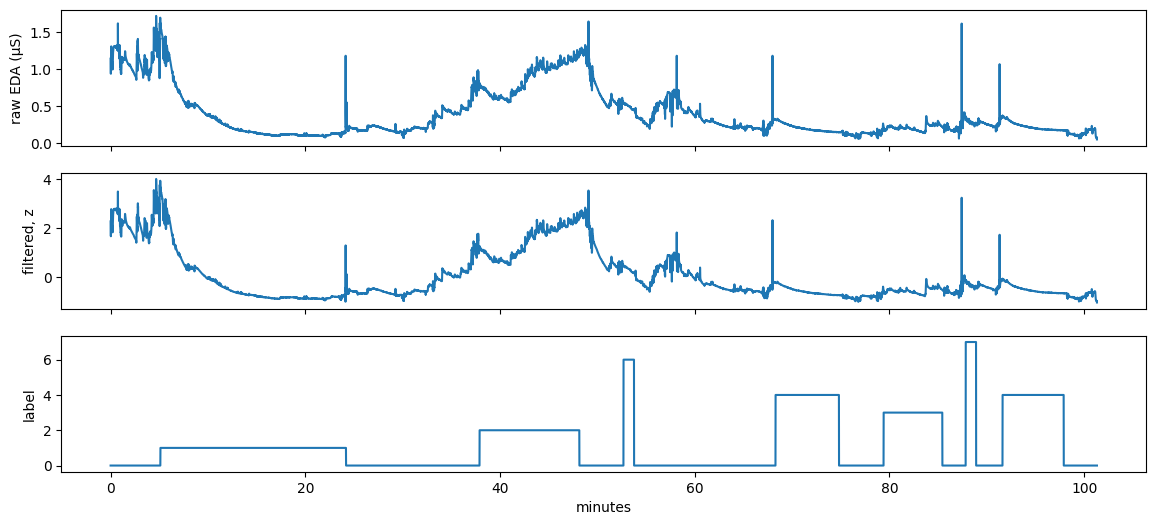

S2: 129 windows  stress=37  non-stress=92
S3: 132 windows  stress=39  non-stress=93
S4: 132 windows  stress=39  non-stress=93
S5: 136 windows  stress=39  non-stress=97
S6: 135 windows  stress=40  non-stress=95
S7: 135 windows  stress=39  non-stress=96
S8: 136 windows  stress=41  non-stress=95
S9: 134 windows  stress=39  non-stress=95
S10: 140 windows  stress=45  non-stress=95
S11: 137 windows  stress=41  non-stress=96
S13: 137 windows  stress=40  non-stress=97
S14: 137 windows  stress=41  non-stress=96
S15: 137 windows  stress=42  non-stress=95
S16: 136 windows  stress=41  non-stress=95
S17: 138 windows  stress=44  non-stress=94


In [7]:
import importlib, numpy as np, matplotlib.pyplot as plt
import src.utils, src.data.preprocess; importlib.reload(src.utils); importlib.reload(src.data.preprocess)
from src.utils import DATA_PROC, load_config
from src.data.preprocess import lowpass, zscore, load_subject
dcfg = load_config()['data']
z = np.load(DATA_PROC / 'S2.npz'); eda, lab = z['eda'], z['labels']
t = np.arange(len(eda)) / dcfg['fs'] / 60
fig, ax = plt.subplots(3, 1, figsize=(14, 6), sharex=True)
ax[0].plot(t, eda); ax[0].set_ylabel('raw EDA (µS)')
ax[1].plot(t, zscore(lowpass(eda.astype(float), dcfg['fs'], dcfg['lowpass_hz'], dcfg['lowpass_order']))); ax[1].set_ylabel('filtered, z')
ax[2].plot(t, lab); ax[2].set_ylabel('label'); ax[2].set_xlabel('minutes'); plt.show()
for s in load_config()['subjects']:
    X, y, _ = load_subject(s); print(f'{s}: {X.shape[0]} windows  stress={y.sum()}  non-stress={(1-y).sum()}')

### 3.3 LOSO split + leakage asserts
**Hard rule:** the held-out subject never touches diffusion, SMOTE, augmentation or classifier training. `assert_no_leakage` checks this everywhere we fit something.

In [8]:
%%writefile ../src/data/loso.py
"""Leave-One-Subject-Out folds, real-data subsampling, and leakage asserts.

A Fold holds training windows from 14 subjects and test windows from 1 subject.
Each window carries its subject id so we can PROVE (assert) that the test
subject never enters diffusion / SMOTE / augmentation / classifier training.
"""
from dataclasses import dataclass

import numpy as np

from src.data.preprocess import load_subject
from src.utils import load_config


@dataclass
class Fold:
    test_subject: str
    X_train: np.ndarray
    y_train: np.ndarray
    s_train: np.ndarray      # subject id per training window
    X_test: np.ndarray
    y_test: np.ndarray

    @property
    def train_subjects(self):
        return sorted(set(self.s_train.tolist()))


def get_fold(test_subject, subjects=None, train_subjects=None):
    subjects = subjects or load_config()["subjects"]
    assert test_subject in subjects
    train_subjects = train_subjects or [s for s in subjects if s != test_subject]
    Xs, ys, ss = [], [], []
    for s in train_subjects:
        X, y, _ = load_subject(s)
        Xs.append(X)
        ys.append(y)
        ss.append(np.full(len(y), s))
    X_te, y_te, _ = load_subject(test_subject)
    fold = Fold(test_subject, np.concatenate(Xs), np.concatenate(ys), np.concatenate(ss), X_te, y_te)
    assert_no_leakage(fold.s_train, test_subject)
    return fold


def assert_no_leakage(subject_ids, test_subject, where="training data"):
    """Hard rule: the held-out subject must never appear in anything we fit."""
    assert test_subject not in set(np.asarray(subject_ids).tolist()), \
        f"LEAKAGE: test subject {test_subject} found in {where}"


def subsample(fold: Fold, frac: float, seed: int):
    """Stratified (subject x class) random fraction of the real training set.

    Keeps at least 1 window per non-empty (subject, class) cell so every
    training subject and both classes stay represented even at 5%.
    """
    if frac >= 1.0:
        return fold.X_train, fold.y_train, fold.s_train
    rng = np.random.default_rng(seed)
    keep = []
    for s in np.unique(fold.s_train):
        for c in (0, 1):
            idx = np.where((fold.s_train == s) & (fold.y_train == c))[0]
            if len(idx) == 0:
                continue
            n = max(1, int(round(frac * len(idx))))
            keep.append(rng.choice(idx, n, replace=False))
    keep = np.sort(np.concatenate(keep))
    return fold.X_train[keep], fold.y_train[keep], fold.s_train[keep]


Overwriting ../src/data/loso.py


**Demo:** one fold, and proof that the assert fires if the test subject is injected.

In [9]:
import src.data.loso; importlib.reload(src.data.loso)
from src.data.loso import get_fold, subsample, assert_no_leakage
fold = get_fold('S2')
print('train subjects:', fold.train_subjects)
print('train windows', len(fold.y_train), '| test windows', len(fold.y_test))
Xr, yr, sr = subsample(fold, 0.05, seed=0); print('5% subset:', len(yr), 'windows, stress', yr.sum(), ', subjects', len(set(sr)))
try:
    assert_no_leakage(np.r_[fold.s_train, ['S2']], 'S2')
except AssertionError as e:
    print('assert works ->', e)

train subjects:

 ['S10', 'S11', 'S13', 'S14', 'S15', 'S16', 'S17', 'S3', 'S4', 'S5', 'S6', 'S7', 'S8', 'S9']
train windows 1902 | test windows 129
5% subset: 98 windows, stress 28 , subjects 14
assert works -> LEAKAGE: test subject S2 found in training data


## 4. Frozen classifier
The same architecture and hyperparameters are used for **every** training-set variant, so differences in F1 come only from the data.

In [10]:
%%writefile ../src/models/classifier.py
"""The FROZEN stress classifier used for every training-set variant (A-F).

Same architecture + same hyperparameters for every variant, so differences in
test F1 come only from the training DATA, not from the model.

Architecture: 3 x [Conv1d(k=7) -> BatchNorm -> ReLU -> MaxPool(2)]
              (channels 32/64/128) -> global average pool -> Dropout -> Linear(2)
Loss: class-weighted cross-entropy (weights from the training set it is given),
so the minority class (stress) is not ignored.
"""
import numpy as np
import torch
import torch.nn as nn
from sklearn.metrics import balanced_accuracy_score, f1_score

from src.utils import set_seed


class StressCNN(nn.Module):
    def __init__(self, n_classes=2, dropout=0.3, in_ch=1):
        super().__init__()
        layers, c = [], in_ch
        for out in (32, 64, 128):
            layers += [nn.Conv1d(c, out, 7, padding=3), nn.BatchNorm1d(out), nn.ReLU(), nn.MaxPool1d(2)]
            c = out
        self.features = nn.Sequential(*layers)
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(c, n_classes))

    def embed(self, x):
        return self.features(x).mean(-1)          # global average pool -> [B, 128]

    def forward(self, x):
        return self.head(self.embed(x))


def train_classifier(X, y, seed, cfg, device, n_classes=2, verbose=False):
    """Train a fresh StressCNN on (X, y). X: [n, L] float, y: [n] int."""
    set_seed(seed)
    model = StressCNN(n_classes, cfg["dropout"]).to(device)
    Xt = torch.tensor(X, dtype=torch.float32).unsqueeze(1)
    yt = torch.tensor(y, dtype=torch.long)
    counts = np.bincount(y, minlength=n_classes).astype(np.float32)
    w = counts.sum() / (n_classes * np.maximum(counts, 1))
    loss_fn = nn.CrossEntropyLoss(weight=torch.tensor(w, device=device))
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"])
    g = torch.Generator().manual_seed(seed)
    n, bs = len(yt), cfg["batch_size"]
    model.train()
    for ep in range(cfg["epochs"]):
        perm = torch.randperm(n, generator=g)
        tot = 0.0
        for i in range(0, n, bs):
            idx = perm[i:i + bs]
            if len(idx) < 2:          # BatchNorm needs >1 sample
                continue
            xb, yb = Xt[idx].to(device), yt[idx].to(device)
            loss = loss_fn(model(xb), yb)
            opt.zero_grad()
            loss.backward()
            opt.step()
            tot += loss.item() * len(idx)
        if verbose and (ep + 1) % 10 == 0:
            print(f"  ep {ep + 1}: loss {tot / n:.4f}")
    model.eval()
    return model


@torch.no_grad()
def predict_proba(model, X, device, bs=512):
    model.eval()
    out = []
    for i in range(0, len(X), bs):
        xb = torch.tensor(X[i:i + bs], dtype=torch.float32).unsqueeze(1).to(device)
        out.append(torch.softmax(model(xb), -1).cpu())
    return torch.cat(out).numpy()


def evaluate(model, X, y, device):
    pred = predict_proba(model, X, device).argmax(1)
    return {
        "macro_f1": float(f1_score(y, pred, average="macro", zero_division=0)),
        "bal_acc": float(balanced_accuracy_score(y, pred)),
    }


Overwriting ../src/models/classifier.py


In [11]:
import src.models.classifier; importlib.reload(src.models.classifier)
from src.models.classifier import StressCNN
m = StressCNN(); print(m); print('params:', sum(p.numel() for p in m.parameters()))

StressCNN(
  (features): Sequential(
    (0): Conv1d(1, 32, kernel_size=(7,), stride=(1,), padding=(3,))
    (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv1d(32, 64, kernel_size=(7,), stride=(1,), padding=(3,))
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv1d(64, 128, kernel_size=(7,), stride=(1,), padding=(3,))
    (9): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (head): Sequential(
    (0): Dropout(p=0.3, inplace=False)
    (1): Linear(in_features=128, out_features=2, bias=True)
  )
)
params: 72834


## 5. Diffusion model
### 5.1 1D U-Net denoiser
Input: noisy window `[B,1,240]`, timestep, label (0/1, or 2 = null for CFG). Encoder 240→120→60, self-attention in the bottleneck, decoder with skip connections. The time + label embedding is added inside every ResBlock.

In [12]:
%%writefile ../src/models/unet1d.py
"""1D U-Net denoiser eps_theta(x_t, t, y).

Input: noisy window x_t [B, 1, 240], timestep t [B], class label y [B]
       (0 non-stress, 1 stress, 2 = "null" label used for classifier-free guidance).
Output: predicted noise eps [B, 1, 240].

Structure
- Conditioning vector c = MLP(sinusoidal(t)) + Embedding(y). It is added
  (as a per-channel bias) inside every ResBlock, so every layer knows how noisy
  the input is and which class to generate.
- Encoder: 240 -> 120 -> 60 samples, channels 64 -> 128 -> 256.
- Bottleneck with self-attention at length 60 (cheap; lets the model relate
  distant parts of the 60 s window, e.g. several SCRs).
- Decoder mirrors the encoder and concatenates skip connections (the "U").
"""
import math

import torch
import torch.nn as nn
import torch.nn.functional as F


def sinusoidal(t, dim):
    half = dim // 2
    freqs = torch.exp(-math.log(10000) * torch.arange(half, device=t.device) / half)
    a = t.float()[:, None] * freqs[None]
    return torch.cat([a.sin(), a.cos()], -1)


class ResBlock(nn.Module):
    def __init__(self, cin, cout, emb_dim, dropout=0.1):
        super().__init__()
        self.n1 = nn.GroupNorm(8, cin)
        self.c1 = nn.Conv1d(cin, cout, 3, padding=1)
        self.emb = nn.Linear(emb_dim, cout)
        self.n2 = nn.GroupNorm(8, cout)
        self.drop = nn.Dropout(dropout)
        self.c2 = nn.Conv1d(cout, cout, 3, padding=1)
        self.skip = nn.Conv1d(cin, cout, 1) if cin != cout else nn.Identity()

    def forward(self, x, c):
        h = self.c1(F.silu(self.n1(x)))
        h = h + self.emb(F.silu(c))[:, :, None]
        h = self.c2(self.drop(F.silu(self.n2(h))))
        return h + self.skip(x)


class Attention(nn.Module):
    def __init__(self, ch, heads=4):
        super().__init__()
        self.norm = nn.GroupNorm(8, ch)
        self.attn = nn.MultiheadAttention(ch, heads, batch_first=True)

    def forward(self, x):
        h = self.norm(x).transpose(1, 2)            # [B, L, C]
        h, _ = self.attn(h, h, h, need_weights=False)
        return x + h.transpose(1, 2)


class UNet1D(nn.Module):
    def __init__(self, channels=(64, 128, 256), emb_dim=128, n_classes=2):
        super().__init__()
        self.emb_dim = emb_dim
        self.t_mlp = nn.Sequential(nn.Linear(emb_dim, emb_dim * 2), nn.SiLU(), nn.Linear(emb_dim * 2, emb_dim))
        self.y_emb = nn.Embedding(n_classes + 1, emb_dim)   # last index = null label
        self.inp = nn.Conv1d(1, channels[0], 3, padding=1)

        self.down = nn.ModuleList()
        self.downsample = nn.ModuleList()
        skips_ch = []
        c = channels[0]
        for i, ch in enumerate(channels):
            self.down.append(nn.ModuleList([ResBlock(c, ch, emb_dim), ResBlock(ch, ch, emb_dim)]))
            c = ch
            skips_ch.append(ch)
            last = i == len(channels) - 1
            self.downsample.append(nn.Identity() if last else nn.Conv1d(ch, ch, 4, stride=2, padding=1))

        self.mid1 = ResBlock(c, c, emb_dim)
        self.mid_attn = Attention(c)
        self.mid2 = ResBlock(c, c, emb_dim)

        self.up = nn.ModuleList()
        self.upsample = nn.ModuleList()
        for i, ch in reversed(list(enumerate(channels))):
            skip = skips_ch[i]
            self.up.append(nn.ModuleList([ResBlock(c + skip, ch, emb_dim), ResBlock(ch, ch, emb_dim)]))
            c = ch
            self.upsample.append(nn.Identity() if i == 0 else nn.ConvTranspose1d(ch, channels[i - 1], 4, stride=2, padding=1))
            if i != 0:
                c = channels[i - 1]

        self.out = nn.Sequential(nn.GroupNorm(8, c), nn.SiLU(), nn.Conv1d(c, 1, 3, padding=1))

    def forward(self, x, t, y):
        c = self.t_mlp(sinusoidal(t, self.emb_dim)) + self.y_emb(y)
        h = self.inp(x)
        skips = []
        for (r1, r2), ds in zip(self.down, self.downsample):
            h = r2(r1(h, c), c)
            skips.append(h)
            h = ds(h)
        h = self.mid2(self.mid_attn(self.mid1(h, c)), c)
        for (r1, r2), us in zip(self.up, self.upsample):
            h = torch.cat([h, skips.pop()], 1)
            h = r2(r1(h, c), c)
            h = us(h)
        return self.out(h)


Overwriting ../src/models/unet1d.py


### 5.2 DDPM with v-prediction, classifier-free guidance, DDIM sampling
**Bug found and fixed:** with ε-prediction, the window *level* exploded (±4.7 SD vs ±0.7 real; 11% clipped). Recovering x₀ from ε divides by √ᾱ ≈ 10⁻⁵ at high noise. v-prediction is well-posed at every noise level.

In [13]:
%%writefile ../src/models/diffusion.py
"""Class-conditional DDPM with classifier-free guidance and DDIM sampling.

Forward (noising) process:  x_t = sqrt(abar_t) * x_0 + sqrt(1 - abar_t) * eps
Training: pick random t, add noise, train UNet to predict eps (MSE loss).
Classifier-free guidance (CFG): with prob p_uncond replace the label by the
"null" label, so ONE network learns both p(x|y) and p(x).
At sampling:  eps = (1 + w) * eps(x, t, y) - w * eps(x, t, null)
  w = 0 -> plain conditional model; larger w -> more class-typical samples
  (and, possibly, more memorization - one of our trade-off curves).
DDIM (eta = 0) sampling uses 50 of the 1000 steps deterministically -> ~20x faster.
"""
import math

import torch
import torch.nn.functional as F


def cosine_alphas_cumprod(T, s=0.008):
    """Nichol & Dhariwal cosine schedule: noise is added smoothly, not too fast at the start."""
    steps = torch.arange(T + 1, dtype=torch.float64) / T
    f = torch.cos((steps + s) / (1 + s) * math.pi / 2) ** 2
    abar = f / f[0]
    betas = (1 - abar[1:] / abar[:-1]).clamp(max=0.999)
    return torch.cumprod(1 - betas, 0).float()


class Diffusion:
    """pred="v": the network predicts v = sqrt(abar)*eps - sqrt(1-abar)*x0.

    Why v and not eps: at the last steps of the cosine schedule abar ~ 0, so
    recovering x0 from an eps-prediction divides by sqrt(abar) ~ 0 and any
    error explodes. For EDA this blew up the window's mean level (the most
    important feature). v-prediction stays well-posed at every noise level
    (Salimans & Ho 2022; Lin et al. 2024).
    """

    def __init__(self, model, T=1000, p_uncond=0.1, n_classes=2, device="cpu", pred="v"):
        self.model = model
        self.T = T
        self.p_uncond = p_uncond
        self.null = n_classes          # index of the null label
        self.device = device
        self.pred = pred
        self.abar = cosine_alphas_cumprod(T).to(device)

    def loss(self, x0, y):
        b = x0.shape[0]
        t = torch.randint(0, self.T, (b,), device=x0.device)
        eps = torch.randn_like(x0)
        ab = self.abar[t][:, None, None]
        xt = ab.sqrt() * x0 + (1 - ab).sqrt() * eps
        drop = torch.rand(b, device=x0.device) < self.p_uncond
        y = torch.where(drop, torch.full_like(y, self.null), y)
        target = eps if self.pred == "eps" else ab.sqrt() * eps - (1 - ab).sqrt() * x0
        return F.mse_loss(self.model(xt, t, y), target)

    def _x0_eps(self, out, x, ab):
        """Convert network output to (x0_hat, eps_hat)."""
        if self.pred == "eps":
            return (x - (1 - ab).sqrt() * out) / ab.sqrt(), out
        x0 = ab.sqrt() * x - (1 - ab).sqrt() * out
        eps = (1 - ab).sqrt() * x + ab.sqrt() * out
        return x0, eps

    @torch.no_grad()
    def sample(self, y, length=240, steps=50, guidance=2.0, model=None, generator=None, clip=8.0):
        """DDIM (eta=0) sampling for a batch of labels y [B]."""
        net = model or self.model
        net.eval()
        b = len(y)
        x = torch.randn(b, 1, length, device=self.device, generator=generator)
        ts = torch.linspace(self.T - 1, 0, steps, device=self.device).long()
        null = torch.full_like(y, self.null)
        for i, t in enumerate(ts):
            tt = t.repeat(b)
            if guidance == 0:
                out = net(x, tt, y)
            else:
                o = net(torch.cat([x, x]), torch.cat([tt, tt]), torch.cat([y, null]))
                oc, ou = o.chunk(2)
                out = (1 + guidance) * oc - guidance * ou   # CFG (linear, so valid for eps or v)
            ab = self.abar[t]
            x0, eps = self._x0_eps(out, x, ab)
            x0 = x0.clamp(-clip, clip)
            ab_prev = self.abar[ts[i + 1]] if i + 1 < len(ts) else torch.tensor(1.0, device=self.device)
            x = ab_prev.sqrt() * x0 + (1 - ab_prev).sqrt() * eps
        return x.squeeze(1)

    def generate(self, n_per_class, guidance=2.0, steps=50, seed=0, bs=512, model=None, length=240):
        """Return (X [N, L] numpy, y [N]) with n_per_class[c] samples of class c."""
        g = torch.Generator(device=self.device).manual_seed(seed)
        Xs, ys = [], []
        for c, n in enumerate(n_per_class):
            for i in range(0, n, bs):
                m = min(bs, n - i)
                y = torch.full((m,), c, device=self.device, dtype=torch.long)
                Xs.append(self.sample(y, length, steps, guidance, model, g).cpu())
                ys.append(torch.full((m,), c))
        return torch.cat(Xs).numpy(), torch.cat(ys).numpy()


Overwriting ../src/models/diffusion.py


### 5.3 Training (per fold, EMA weights, milestone checkpoints)

In [14]:
%%writefile ../src/train_diffusion.py
"""Train the class-conditional diffusion model on ONE fold's training subjects.

- Input data: fold.X_train / fold.y_train only (asserted: no test subject).
- EMA (exponential moving average) weights are used for sampling: they are a
  smoothed average of the training weights and give cleaner samples.
- Milestone checkpoints (fp16, EMA weights) are saved at 25/50/100% of epochs
  for the utility-vs-memorization-over-epochs curve.
"""
import copy

import numpy as np
import torch

from src.data.loso import assert_no_leakage
from src.models.diffusion import Diffusion
from src.models.unet1d import UNet1D
from src.utils import CKPT_DIR, log, set_seed


def build(cfg, device):
    net = UNet1D(tuple(cfg["channels"]), cfg["emb_dim"]).to(device)
    return net, Diffusion(net, cfg["T"], cfg["p_uncond"], device=device, pred=cfg.get("pred", "v"))


@torch.no_grad()
def ema_update(ema, net, decay):
    for pe, p in zip(ema.parameters(), net.parameters()):
        pe.mul_(decay).add_(p.detach(), alpha=1 - decay)
    for be, b in zip(ema.buffers(), net.buffers()):
        be.copy_(b)


def ckpt_path(tag, milestone):
    return CKPT_DIR / tag / f"ema_{int(milestone * 100):03d}.pt"


def train_diffusion(X, y, s_ids, test_subject, cfg, device, tag, seed=0, epochs=None):
    """Return (ema_model, diffusion, loss_history). Saves milestone checkpoints under results/ckpt/<tag>/."""
    assert_no_leakage(s_ids, test_subject, "diffusion training set")
    set_seed(seed)
    epochs = epochs or cfg["epochs"]
    net, diff = build(cfg, device)
    ema = copy.deepcopy(net).eval()
    for p in ema.parameters():
        p.requires_grad_(False)
    opt = torch.optim.AdamW(net.parameters(), lr=cfg["lr"], weight_decay=1e-4)
    Xt = torch.tensor(X, dtype=torch.float32).unsqueeze(1).to(device)
    yt = torch.tensor(y, dtype=torch.long).to(device)
    n, bs = len(yt), cfg["batch_size"]
    g = torch.Generator(device="cpu").manual_seed(seed)
    milestones = {max(1, int(round(m * epochs))): m for m in cfg["milestones"]}
    hist = []
    (CKPT_DIR / tag).mkdir(parents=True, exist_ok=True)
    for ep in range(1, epochs + 1):
        net.train()
        perm = torch.randperm(n, generator=g).to(device)
        tot = 0.0
        for i in range(0, n, bs):
            idx = perm[i:i + bs]
            loss = diff.loss(Xt[idx], yt[idx])
            opt.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(net.parameters(), 1.0)
            opt.step()
            ema_update(ema, net, cfg["ema"])
            tot += loss.item() * len(idx)
        hist.append(tot / n)
        if ep % 50 == 0 or ep == 1:
            log(f"  diffusion ep {ep}/{epochs} loss {hist[-1]:.4f}")
        if ep in milestones:
            sd = {k: v.half() if v.is_floating_point() else v for k, v in ema.state_dict().items()}
            torch.save(sd, ckpt_path(tag, milestones[ep]))
    diff.model = ema
    return ema, diff, hist


def load_ema(cfg, device, tag, milestone=1.0):
    net, diff = build(cfg, device)
    sd = torch.load(ckpt_path(tag, milestone), map_location=device, weights_only=True)
    net.load_state_dict({k: v.float() if v.is_floating_point() else v for k, v in sd.items()})
    net.eval()
    diff.model = net
    return net, diff


Overwriting ../src/train_diffusion.py


In [15]:
import src.models.unet1d, src.models.diffusion; importlib.reload(src.models.unet1d); importlib.reload(src.models.diffusion)
from src.models.unet1d import UNet1D
from src.models.diffusion import Diffusion
net = UNet1D(); print('U-Net params: %.2f M' % (sum(p.numel() for p in net.parameters())/1e6))
d = Diffusion(net, pred='v')
xb = torch.tensor(fold.X_train[:8]).unsqueeze(1); yb = torch.tensor(fold.y_train[:8])
print('one training loss (untrained):', d.loss(xb, yb).item())
print('output shape:', net(xb, torch.zeros(8, dtype=torch.long), yb).shape)

U-Net params: 4.09 M


one training loss (untrained): 2.48551869392395
output shape: torch.Size([8, 1, 240])


## 6. Baselines
- **E, SMOTE:** interpolates between same-class neighbours.
- **F, augmentation:** jitter, scaling, time-warp, tonic drift, Bateman-shaped SCR insertion.
- **C, diffusion:** `synth_fill`.

All three fill each class up to the same K, so they are size-matched.

In [16]:
%%writefile ../src/baselines.py
"""Classical baselines that compete with diffusion synthetic data.

All of them take ONLY the small-real training subset (never test data) and
fill each class up to the same target count K as the diffusion variant C, so
the comparison is size-matched.

E: SMOTE - new window = a + u * (b - a), with b one of the k nearest
   same-class neighbours of a (u ~ U(0,1)). Interpolates in 240-D space.
F: Time-series augmentation of random real windows:
   - jitter: + Gaussian noise
   - scaling: multiply by ~N(1, sigma)
   - time-warp: smooth random speed-up/slow-down of the time axis
   - EDA-specific: tonic drift (slow random baseline change) and
     SCR insertion (Bateman-shaped phasic bumps: fast rise, slow decay).
"""
import numpy as np
from imblearn.over_sampling import SMOTE
from scipy.interpolate import CubicSpline


def smote_fill(X, y, K, seed):
    counts = np.bincount(y, minlength=2)
    k = int(max(1, min(5, counts.min() - 1)))
    sm = SMOTE(sampling_strategy={c: int(max(K, counts[c])) for c in (0, 1)}, k_neighbors=k, random_state=seed)
    return sm.fit_resample(X, y)


# ---------- augmentation primitives (x: [L]) ----------
def jitter(x, rng, sigma):
    return x + rng.normal(0, sigma, x.shape)


def scaling(x, rng, sigma):
    return x * rng.normal(1, sigma)


def time_warp(x, rng, sigma, knots):
    L = len(x)
    pos = np.linspace(0, L - 1, knots + 2)
    speed = CubicSpline(pos, rng.normal(1, sigma, knots + 2))(np.arange(L))
    t = np.cumsum(np.clip(speed, 0.1, None))
    t = (t - t[0]) / (t[-1] - t[0]) * (L - 1)
    return np.interp(np.arange(L), t, x)


def tonic_drift(x, rng, sigma):
    L = len(x)
    pos = np.linspace(0, L - 1, 4)
    return x + CubicSpline(pos, rng.normal(0, sigma, 4))(np.arange(L))


def bateman(L, fs, onset, tau_rise=0.75, tau_decay=2.0):
    t = (np.arange(L) - onset) / fs
    s = np.where(t > 0, np.exp(-t / tau_decay) - np.exp(-t / tau_rise), 0.0)
    return s / (s.max() + 1e-8)


def scr_insert(x, rng, rate_per_min, amp, fs=4):
    L = len(x)
    n = rng.poisson(rate_per_min * L / fs / 60)
    out = x.copy()
    for _ in range(n):
        out += amp * rng.uniform(0.3, 1.0) * bateman(L, fs, rng.integers(0, L - fs * 4))
    return out


def augment_one(x, rng, cfg):
    x = jitter(x, rng, cfg["jitter_sigma"])
    x = scaling(x, rng, cfg["scale_sigma"])
    x = time_warp(x, rng, cfg["warp_sigma"], cfg["warp_knots"])
    if rng.random() < 0.5:
        x = tonic_drift(x, rng, cfg["drift_sigma"])
    if rng.random() < 0.5:
        x = scr_insert(x, rng, cfg["scr_rate_per_min"], cfg["scr_amp"])
    return x


def augment_fill(X, y, K, seed, cfg):
    rng = np.random.default_rng(seed)
    Xo, yo = [X], [y]
    for c in (0, 1):
        idx = np.where(y == c)[0]
        need = K - len(idx)
        if need <= 0 or len(idx) == 0:
            continue
        src = rng.choice(idx, need, replace=True)
        Xo.append(np.stack([augment_one(X[i].astype(np.float64), rng, cfg) for i in src]).astype(np.float32))
        yo.append(np.full(need, c))
    return np.concatenate(Xo), np.concatenate(yo)


def synth_fill(X, y, K, Xs, ys, seed):
    """Variant C: add synthetic windows (from the fold's diffusion pool) up to K per class."""
    rng = np.random.default_rng(seed)
    Xo, yo = [X], [y]
    for c in (0, 1):
        need = K - int((y == c).sum())
        if need <= 0:
            continue
        pool = np.where(ys == c)[0]
        pick = rng.choice(pool, need, replace=need > len(pool))
        Xo.append(Xs[pick])
        yo.append(ys[pick])
    return np.concatenate(Xo), np.concatenate(yo)


Overwriting ../src/baselines.py


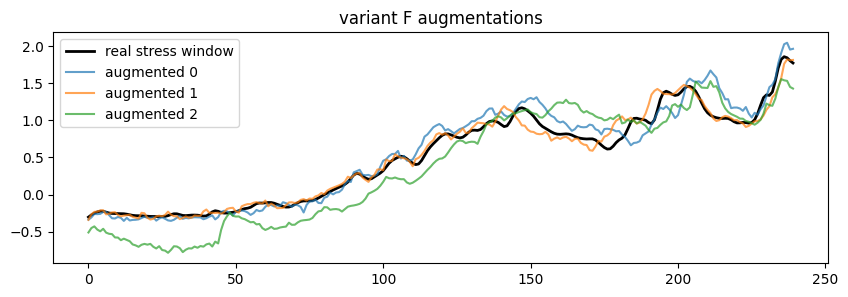

In [17]:
import src.baselines; importlib.reload(src.baselines)
from src.baselines import augment_one
acfg = load_config()['augment']; rng = np.random.default_rng(0)
x0 = fold.X_train[fold.y_train == 1][5].astype(float)
plt.figure(figsize=(10, 3)); plt.plot(x0, 'k', lw=2, label='real stress window')
for i in range(3): plt.plot(augment_one(x0, rng, acfg), alpha=.7, label=f'augmented {i}')
plt.legend(); plt.title('variant F augmentations'); plt.show()

## 7. Tests
### 7.1 Test 0: Fidelity
Moments, PSD, MMD, DTW, discriminative score and EDA features. Each is compared with an *unseen real subject* reference.

In [18]:
%%writefile ../src/eval/fidelity.py
"""Test 0 - Fidelity: does synthetic EDA look/behave like real EDA?

Each metric compares synthetic windows with the fold's REAL TRAINING windows,
per class. The held-out subject's real windows give an "unseen real person"
reference: a good generator should be about as close to train-real as a new
real person is.

- moments: per-window mean / std / skewness / kurtosis distributions
- PSD: Welch power spectrum (fs = 4 Hz), averaged, log-distance
- histogram / KDE of sample values (saved for plots)
- MMD: kernel two-sample distance (RBF, median-heuristic bandwidth); 0 = same distribution
- DTW: shape distance allowing small time shifts (Sakoe-Chiba band)
- discriminative score: |accuracy - 0.5| of a CNN trained to tell real from synthetic
  (0 = indistinguishable, 0.5 = trivially separable)
- EDA physiology: tonic level (SCL), SCR rate and amplitude via neurokit2
"""
import warnings

import numpy as np
import torch
from scipy.signal import welch
from scipy.stats import kurtosis, ks_2samp, skew

from src.models.classifier import evaluate, train_classifier

warnings.filterwarnings("ignore", module="neurokit2")


def moments(X):
    return {"mean": X.mean(1), "std": X.std(1), "skew": skew(X, 1), "kurt": kurtosis(X, 1)}


def moment_summary(Xr, Xs):
    mr, ms = moments(Xr), moments(Xs)
    return {k: {"real_mean": float(np.mean(mr[k])), "synth_mean": float(np.mean(ms[k])),
                "real_std": float(np.std(mr[k])), "synth_std": float(np.std(ms[k])),
                "ks": float(ks_2samp(mr[k], ms[k]).statistic)} for k in mr}


def psd(X, fs=4):
    f, p = welch(X, fs=fs, nperseg=120, axis=1)
    return f, p.mean(0)


def psd_distance(Xr, Xs, fs=4):
    f, pr = psd(Xr, fs)
    _, ps = psd(Xs, fs)
    return float(np.sqrt(np.mean((np.log10(pr + 1e-10) - np.log10(ps + 1e-10)) ** 2))), f, pr, ps


def mmd_rbf(A, B, max_n=600, seed=0, device="cpu"):
    rng = np.random.default_rng(seed)
    A = A[rng.choice(len(A), min(max_n, len(A)), replace=False)]
    B = B[rng.choice(len(B), min(max_n, len(B)), replace=False)]
    a = torch.tensor(A, device=device, dtype=torch.float64)
    b = torch.tensor(B, device=device, dtype=torch.float64)
    z = torch.cat([a, b])
    d2 = torch.cdist(z, z) ** 2
    sigma2 = torch.median(d2[d2 > 0])                     # median heuristic
    k = torch.exp(-d2 / sigma2)
    n, m = len(a), len(b)
    kaa = (k[:n, :n].sum() - k[:n, :n].diag().sum()) / (n * (n - 1))
    kbb = (k[n:, n:].sum() - k[n:, n:].diag().sum()) / (m * (m - 1))
    kab = k[:n, n:].mean()
    return float(kaa + kbb - 2 * kab)


def dtw(a, b, band):
    n = len(a)
    D = np.full((n + 1, n + 1), np.inf)
    D[0, 0] = 0
    for i in range(1, n + 1):
        lo, hi = max(1, i - band), min(n, i + band)
        cost = np.abs(a[i - 1] - b[lo - 1:hi])
        for j in range(lo, hi + 1):
            D[i, j] = cost[j - lo] + min(D[i - 1, j], D[i, j - 1], D[i - 1, j - 1])
    return D[n, n] / n


def mean_dtw(A, B, pairs, band, seed=0):
    rng = np.random.default_rng(seed)
    ia, ib = rng.integers(0, len(A), pairs), rng.integers(0, len(B), pairs)
    return float(np.mean([dtw(A[i], B[j], band) for i, j in zip(ia, ib)]))


def discriminative_score(Xr, Xs, clf_cfg, device, seed=0):
    rng = np.random.default_rng(seed)
    n = min(len(Xr), len(Xs))
    Xr = Xr[rng.choice(len(Xr), n, replace=False)]
    Xs = Xs[rng.choice(len(Xs), n, replace=False)]
    X = np.concatenate([Xr, Xs])
    y = np.r_[np.zeros(n, int), np.ones(n, int)]
    perm = rng.permutation(len(y))
    cut = int(0.8 * len(y))
    tr, te = perm[:cut], perm[cut:]
    cfg = dict(clf_cfg, epochs=20)
    m = train_classifier(X[tr], y[tr], seed, cfg, device)
    acc = evaluate(m, X[te], y[te], device)["bal_acc"]
    return float(abs(acc - 0.5))


def eda_features(X, fs=4, max_n=300, seed=0):
    """Per-window SCL (tonic mean), SCR rate (/min) and mean SCR amplitude."""
    import neurokit2 as nk
    rng = np.random.default_rng(seed)
    X = X[rng.choice(len(X), min(max_n, len(X)), replace=False)]
    scl, rate, amp = [], [], []
    for x in X:
        try:
            ph = nk.eda_phasic(x.astype(np.float64), sampling_rate=fs, method="highpass")
            _, info = nk.eda_peaks(ph["EDA_Phasic"].values, sampling_rate=fs, amplitude_min=0.05)
            peaks = np.asarray(info["SCR_Peaks"])
            a = np.asarray(info["SCR_Amplitude"], dtype=float)
            scl.append(float(ph["EDA_Tonic"].mean()))
            rate.append(len(peaks) / (len(x) / fs / 60))
            amp.append(float(np.nanmean(a)) if len(a) else 0.0)
        except Exception:
            continue
    return {"scl": np.array(scl), "scr_rate": np.array(rate), "scr_amp": np.array(amp)}


def eda_feature_summary(Xr, Xs):
    fr, fs_ = eda_features(Xr), eda_features(Xs)
    return {k: {"real_mean": float(np.mean(fr[k])), "synth_mean": float(np.mean(fs_[k])),
                "real_std": float(np.std(fr[k])), "synth_std": float(np.std(fs_[k])),
                "ks": float(ks_2samp(fr[k], fs_[k]).statistic)} for k in fr}


def run_fidelity(fold, Xs, ys, cfg, device):
    """Return (metrics dict, arrays dict for plotting)."""
    out, arrays = {}, {}
    mcfg = cfg["memorization"]
    for c, name in ((0, "nonstress"), (1, "stress")):
        Xr, Xsy, Xte = fold.X_train[fold.y_train == c], Xs[ys == c], fold.X_test[fold.y_test == c]
        d_psd, f, pr, ps = psd_distance(Xr, Xsy)
        res = {
            "moments": moment_summary(Xr, Xsy),
            "psd_logrmse": d_psd,
            "psd_logrmse_testreal": psd_distance(Xr, Xte)[0] if len(Xte) else None,
            "mmd": mmd_rbf(Xr, Xsy, device=device),
            "mmd_testreal": mmd_rbf(Xr, Xte, device=device) if len(Xte) > 2 else None,
            "dtw_synth_real": mean_dtw(Xsy, Xr, mcfg["dtw_pairs"], mcfg["dtw_band"]),
            "dtw_real_real": mean_dtw(Xr, Xr, mcfg["dtw_pairs"], mcfg["dtw_band"], seed=1),
            "eda": eda_feature_summary(Xr, Xsy),
        }
        out[name] = res
        arrays[f"psd_f"] = f
        arrays[f"psd_real_{name}"] = pr
        arrays[f"psd_synth_{name}"] = ps
        arrays[f"hist_real_{name}"] = np.histogram(Xr, bins=60, range=(-4, 6), density=True)[0]
        arrays[f"hist_synth_{name}"] = np.histogram(Xsy, bins=60, range=(-4, 6), density=True)[0]
    out["discriminative_score"] = discriminative_score(fold.X_train, Xs, cfg["classifier"], device)
    return out, arrays


Overwriting ../src/eval/fidelity.py


### 7.2 Test 1: Utility
Variants A–F × fractions 5/10/25/50/100% × 3 seeds. Metric: macro-F1 / balanced accuracy on the held-out subject.

In [19]:
%%writefile ../src/eval/utility.py
"""Test 1 - Utility: does synthetic data help a stress classifier on an UNSEEN subject?

Training-set variants (same frozen classifier for all):
  A  100% real
  B  100% synthetic (K windows per class)
  C  small real (f%) + synthetic, filled to K per class
  D  small real only
  E  small real + SMOTE to K per class
  F  small real + jitter/scale/time-warp/EDA augmentation to K per class
K = majority-class count of the full real training set (so C/E/F are size-matched).
Evaluated on the held-out subject: macro-F1 and balanced accuracy.
"""
import numpy as np

from src.baselines import augment_fill, smote_fill, synth_fill
from src.data.loso import assert_no_leakage, subsample
from src.models.classifier import evaluate, train_classifier
from src.utils import log


def target_K(y):
    return int(np.bincount(y, minlength=2).max())


def build_variant(variant, fold, frac, seed, Xs, ys, K, cfg):
    """Return the (X, y) training set for one variant/fraction/seed."""
    if variant == "B":
        rng = np.random.default_rng(seed)
        pick = np.concatenate([rng.choice(np.where(ys == c)[0], K, replace=(ys == c).sum() < K) for c in (0, 1)])
        return Xs[pick], ys[pick]
    Xr, yr, sr = subsample(fold, frac, seed=1000 * seed + int(frac * 100))
    assert_no_leakage(sr, fold.test_subject, f"variant {variant} real subset")
    if variant in ("A", "D"):
        return Xr, yr
    if variant == "C":
        return synth_fill(Xr, yr, K, Xs, ys, seed)
    if variant == "E":
        return smote_fill(Xr, yr, K, seed)
    if variant == "F":
        return augment_fill(Xr, yr, K, seed, cfg["augment"])
    raise ValueError(variant)


def run_one(variant, fold, frac, seed, Xs, ys, K, cfg, device, return_model=False):
    X, y = build_variant(variant, fold, frac, seed, Xs, ys, K, cfg)
    m = train_classifier(X, y, seed, cfg["classifier"], device)
    r = evaluate(m, fold.X_test, fold.y_test, device)
    r.update(variant=variant, frac=frac, seed=seed, n_train=len(y), n_stress=int(y.sum()))
    return (r, m) if return_model else r


def run_utility(fold, Xs, ys, cfg, device):
    """All variants x fractions x seeds for one fold. Returns (records, A-model seed 0)."""
    K = target_K(fold.y_train)
    seeds = cfg["classifier"]["seeds"]
    recs, model_A = [], None
    for seed in seeds:
        r, m = run_one("A", fold, 1.0, seed, Xs, ys, K, cfg, device, return_model=True)
        recs.append(r)
        if seed == seeds[0]:
            model_A = m
        recs.append(run_one("B", fold, 1.0, seed, Xs, ys, K, cfg, device))
        for frac in cfg["utility"]["fractions"]:
            for v in ("C", "D", "E", "F"):
                if v == "D" and frac >= 1.0:   # D at 100% is exactly A: reuse, don't retrain
                    a = next(x for x in recs if x["variant"] == "A" and x["seed"] == seed)
                    recs.append({**a, "variant": "D"})
                    continue
                recs.append(run_one(v, fold, frac, seed, Xs, ys, K, cfg, device))
        log(f"  utility seed {seed} done")
    return recs, model_A


Overwriting ../src/eval/utility.py


### 7.3 Test 2: Memorization audit
DCR vs unseen-real baseline, NNDR, per-subject nearest-neighbour share, subject re-ID and distance-based membership inference. **A memorization audit, not a privacy guarantee.**

In [20]:
%%writefile ../src/eval/memorization.py
"""Test 2 - Memorization audit (NOT a privacy guarantee).

Question: are synthetic windows near-copies of specific training windows?

- DCR (distance to closest record): Euclidean distance from each synthetic
  window to its nearest REAL TRAINING window.
  Baseline: DCR of the held-out subject's real windows to the same training set.
  That subject was never seen, so its DCR shows how close an UNSEEN real
  person naturally gets. If synthetic DCR << baseline DCR -> copying.
- NNDR: nearest / 2nd-nearest distance. Values near 0 mean "one training window
  is much closer than all others" (typical of a copy).
- Per-subject breakdown: which training subject owns each synthetic sample's
  nearest neighbour; compared with that subject's share of the training data
  (chi-square). Over-represented subjects = the model leans on them.
- Subject re-identification: a CNN learns to tell the 14 training subjects
  apart. If it is as confident on synthetic windows as on held-out windows of
  known subjects, synthetic windows carry subject identity.
- Distance-based membership inference: score = -(distance to nearest synthetic).
  Members = training windows, non-members = held-out subject. AUC 0.5 = no
  membership signal.
"""
import numpy as np
import torch
from scipy.stats import chisquare, mannwhitneyu
from sklearn.metrics import roc_auc_score

from src.models.classifier import predict_proba, train_classifier


def nn_dists(Q, R, device, k=2, bs=2048):
    """Return (dist [n,k], idx [n,k]) of the k nearest rows of R for each row of Q."""
    Rt = torch.tensor(R, device=device, dtype=torch.float32)
    ds, ix = [], []
    for i in range(0, len(Q), bs):
        q = torch.tensor(Q[i:i + bs], device=device, dtype=torch.float32)
        d = torch.cdist(q, Rt)
        v, j = d.topk(k, dim=1, largest=False)
        ds.append(v.cpu())
        ix.append(j.cpu())
    return torch.cat(ds).numpy(), torch.cat(ix).numpy()


def dcr_stats(Xs, X_train, X_ref, device):
    ds, idx = nn_dists(Xs, X_train, device)
    dr, _ = nn_dists(X_ref, X_train, device)
    dcr_s, dcr_r = ds[:, 0], dr[:, 0]
    nndr_s = ds[:, 0] / (ds[:, 1] + 1e-8)
    nndr_r = dr[:, 0] / (dr[:, 1] + 1e-8)
    p5 = np.percentile(dcr_r, 5)
    return {
        "dcr_synth_median": float(np.median(dcr_s)),
        "dcr_ref_median": float(np.median(dcr_r)),
        "dcr_ratio": float(np.median(dcr_s) / np.median(dcr_r)),
        "frac_synth_below_ref_p5": float(np.mean(dcr_s < p5)),
        "mwu_p_synth_closer": float(mannwhitneyu(dcr_s, dcr_r, alternative="less").pvalue),
        "nndr_synth_median": float(np.median(nndr_s)),
        "nndr_ref_median": float(np.median(nndr_r)),
    }, dcr_s, dcr_r, idx[:, 0]


def per_subject_breakdown(nn_idx, s_train):
    subs, counts = np.unique(s_train, return_counts=True)
    owner = s_train[nn_idx]
    obs = np.array([(owner == s).sum() for s in subs])
    exp = counts / counts.sum() * len(nn_idx)
    share = obs / obs.sum()
    return {
        "observed_share": {s: float(v) for s, v in zip(subs, share)},
        "expected_share": {s: float(v) for s, v in zip(subs, counts / counts.sum())},
        "chi2_p": float(chisquare(obs, exp).pvalue),
        "max_over_expected": float(np.max(share / (counts / counts.sum()))),
    }


def membership_auc(X_members, X_nonmembers, Xs, device):
    dm, _ = nn_dists(X_members, Xs, device, k=1)
    dn, _ = nn_dists(X_nonmembers, Xs, device, k=1)
    y = np.r_[np.ones(len(dm)), np.zeros(len(dn))]
    score = -np.r_[dm[:, 0], dn[:, 0]]
    return float(roc_auc_score(y, score))


def reid_split(s_train, block=10, gap=3):
    """Within-subject time-block split for the re-ID classifier.

    Windows overlap (stride 15 s, length 60 s), so neighbours share data.
    Every 5th block of 10 consecutive windows is held out, and train windows
    within `gap` positions of a held-out block are dropped (no overlap leak).
    """
    tr, te = [], []
    for s in np.unique(s_train):
        idx = np.where(s_train == s)[0]          # already in time order
        pos = np.arange(len(idx))
        held = (pos // block) % 5 == 4
        near = np.zeros(len(idx), bool)
        for p in np.where(held)[0]:
            near[max(0, p - gap):p + gap + 1] = True
        te.append(idx[held])
        tr.append(idx[~near])
    return np.concatenate(tr), np.concatenate(te)


def subject_reid(fold, Xs, clf_cfg, device, seed=0):
    subs = sorted(set(fold.s_train.tolist()))
    lab = np.array([subs.index(s) for s in fold.s_train])
    tr, te = reid_split(fold.s_train)
    m = train_classifier(fold.X_train[tr], lab[tr], seed, clf_cfg, device, n_classes=len(subs))

    def conf(X):
        p = predict_proba(m, X, device)
        ent = -(p * np.log(p + 1e-12)).sum(1)
        return float(p.max(1).mean()), float(ent.mean())

    p_te = predict_proba(m, fold.X_train[te], device)
    c_in, e_in = conf(fold.X_train[te])
    c_syn, e_syn = conf(Xs)
    c_new, e_new = conf(fold.X_test)
    return {
        "reid_acc_heldout_known": float((p_te.argmax(1) == lab[te]).mean()),
        "chance": 1 / len(subs),
        "maxprob_known_subject": c_in, "entropy_known_subject": e_in,
        "maxprob_synthetic": c_syn, "entropy_synthetic": e_syn,
        "maxprob_unseen_subject": c_new, "entropy_unseen_subject": e_new,
    }


def run_memorization(fold, Xs, ys, cfg, device, full=True):
    stats, dcr_s, dcr_r, nn_idx = dcr_stats(Xs, fold.X_train, fold.X_test, device)
    out = {"dcr": stats,
           "mia_auc": membership_auc(fold.X_train, fold.X_test, Xs, device)}
    if full:
        out["per_subject"] = per_subject_breakdown(nn_idx, fold.s_train)
        out["per_class_dcr_ratio"] = {
            str(c): dcr_stats(Xs[ys == c], fold.X_train, fold.X_test, device)[0]["dcr_ratio"] for c in (0, 1)}
        out["reid"] = subject_reid(fold, Xs, cfg["classifier"], device)
    return out, {"dcr_synth": dcr_s, "dcr_ref": dcr_r}


Overwriting ../src/eval/memorization.py


## 8. Novelty extras
### 8.1 Utility–memorization trade-off curves (epochs, guidance, # training subjects)
`generate_pool` also applies the **same 1 Hz low-pass** as the real data. Without it, the PSD error was 3.2; with it, 0.3 (the real-vs-real reference is 0.4).

In [21]:
%%writefile ../src/experiments/curves.py
"""Novelty extra: utility-vs-memorization trade-off curves.

Each point on a curve = (utility, memorization) for one generator setting:
  utility      = macro-F1 of variant C at 10% real (mean over classifier seeds)
  memorization = DCR ratio (synthetic DCR / unseen-subject DCR; < 1 = closer
                 to training data than a new person is) and membership AUC.
Settings varied:
  - training epochs   (milestone checkpoints 25/50/100%)
  - guidance scale w  (sampling only; same model)
  - # training subjects for the diffusion model (4 / 8 / 14), with the number
    of gradient steps held constant so only data size changes.
"""
import dataclasses

import numpy as np

from src.data.loso import assert_no_leakage
from src.data.preprocess import lowpass
from src.eval.memorization import run_memorization
from src.eval.utility import run_one, target_K
from src.train_diffusion import load_ema, train_diffusion
from src.utils import log


def generate_pool(diff, K, cfg, guidance=None, seed=0):
    """Sample K windows per class, then apply the SAME 1 Hz low-pass as real data.

    Real windows were low-passed in preprocessing; without this the sampler's
    residual >1 Hz noise made the synthetic PSD ~10x off on a log scale.
    """
    d = cfg["diffusion"]
    g = d["guidance"] if guidance is None else guidance
    X, y = diff.generate([K, K], guidance=g, steps=d["ddim_steps"], seed=seed)
    dc = cfg["data"]
    X = lowpass(X.astype(np.float64), dc["fs"], dc["lowpass_hz"], dc["lowpass_order"]).astype(np.float32)
    return X, y


def tradeoff_point(fold, Xs, ys, cfg, device, mem_fold=None):
    K = target_K(fold.y_train)
    f1 = [run_one("C", fold, 0.10, s, Xs, ys, K, cfg, device)["macro_f1"] for s in cfg["classifier"]["seeds"]]
    mem, _ = run_memorization(mem_fold or fold, Xs, ys, cfg, device, full=False)
    return {"util_C10_f1": float(np.mean(f1)), "dcr_ratio": mem["dcr"]["dcr_ratio"],
            "frac_below_p5": mem["dcr"]["frac_synth_below_ref_p5"], "mia_auc": mem["mia_auc"]}


def epoch_curve(fold, cfg, device, tag, final_point):
    out = {}
    for m in cfg["diffusion"]["milestones"]:
        if m == 1.0:
            out["1.0"] = final_point
            continue
        _, diff = load_ema(cfg["diffusion"], device, tag, m)
        Xs, ys = generate_pool(diff, target_K(fold.y_train), cfg)
        out[str(m)] = tradeoff_point(fold, Xs, ys, cfg, device)
        log(f"  epoch-curve {m}: {out[str(m)]}")
    return out


def guidance_curve(fold, diff, cfg, device, final_point):
    out = {}
    for w in cfg["curves"]["guidance"]:
        if w == cfg["diffusion"]["guidance"]:
            out[str(w)] = final_point
            continue
        Xs, ys = generate_pool(diff, target_K(fold.y_train), cfg, guidance=w)
        out[str(w)] = tradeoff_point(fold, Xs, ys, cfg, device)
        log(f"  guidance-curve w={w}: {out[str(w)]}")
    return out


def subject_curve(fold, cfg, device, full_point):
    """Retrain diffusion on n of the 14 training subjects (fixed #gradient steps)."""
    out = {}
    subs = fold.train_subjects
    rng = np.random.default_rng(0)
    order = list(rng.permutation(subs))
    for n in cfg["curves"]["n_train_subjects"]:
        if n >= len(subs):
            out[str(n)] = full_point
            continue
        chosen = order[:n]
        mask = np.isin(fold.s_train, chosen)
        assert_no_leakage(fold.s_train[mask], fold.test_subject, "subject-curve diffusion set")
        epochs = int(round(cfg["diffusion"]["epochs"] * len(fold.y_train) / mask.sum()))
        _, diff, _ = train_diffusion(fold.X_train[mask], fold.y_train[mask], fold.s_train[mask],
                                     fold.test_subject, cfg["diffusion"], device,
                                     tag=f"{fold.test_subject}_n{n}", epochs=epochs)
        Xs, ys = generate_pool(diff, target_K(fold.y_train), cfg)
        # memorization is measured against the windows this model was trained on
        mem_fold = dataclasses.replace(fold, X_train=fold.X_train[mask], y_train=fold.y_train[mask],
                                       s_train=fold.s_train[mask])
        out[str(n)] = {**tradeoff_point(fold, Xs, ys, cfg, device, mem_fold=mem_fold),
                       "subjects": chosen, "epochs": epochs}
        log(f"  subject-curve n={n}: {out[str(n)]}")
    return out


Overwriting ../src/experiments/curves.py


### 8.2 Replacement (random vs stress-targeted) + mixed-set property check

In [22]:
%%writefile ../src/experiments/replacement.py
"""Novelty extras: replacement experiments and a property check on mixed sets.

Replacement: start from 100% real training data and swap some real windows
for synthetic windows of the SAME label, keeping the set size fixed.
  random   : the swapped windows are drawn from all real windows
  targeted : the same NUMBER of swapped windows, but only stress windows
             (capped at the number of stress windows)
If utility barely drops, synthetic windows are good substitutes for real ones.

Property check on mixed real+synthetic sets (variant C):
  - class balance and synthetic share of the set
  - per-class moment drift of the mixed set vs pure real
  - label consistency: the 100%-real classifier (variant A) predicts the label
    the diffusion model was conditioned on? (conditional fidelity)
"""
import numpy as np

from src.baselines import synth_fill
from src.data.loso import subsample
from src.eval.fidelity import moments
from src.eval.utility import target_K
from src.models.classifier import evaluate, predict_proba, train_classifier


def replace_set(fold, Xs, ys, rate, mode, seed):
    rng = np.random.default_rng(seed)
    X, y = fold.X_train.copy(), fold.y_train.copy()
    n_rep = int(round(rate * len(y)))
    if mode == "random":
        idx = rng.choice(len(y), n_rep, replace=False)
    else:
        stress = np.where(y == 1)[0]
        idx = rng.choice(stress, min(n_rep, len(stress)), replace=False)
    for c in (0, 1):
        tgt = idx[y[idx] == c]
        pool = np.where(ys == c)[0]
        X[tgt] = Xs[rng.choice(pool, len(tgt), replace=len(tgt) > len(pool))]
    return X, y, len(idx)


def run_replacement(fold, Xs, ys, cfg, device):
    recs = []
    for rate in cfg["replacement"]["rates"]:
        for mode in ("random", "targeted"):
            for seed in cfg["classifier"]["seeds"]:
                X, y, n = replace_set(fold, Xs, ys, rate, mode, seed)
                m = train_classifier(X, y, seed, cfg["classifier"], device)
                r = evaluate(m, fold.X_test, fold.y_test, device)
                r.update(rate=rate, mode=mode, seed=seed, n_replaced=n)
                recs.append(r)
    return recs


def property_check(fold, Xs, ys, model_A, cfg, device):
    p = predict_proba(model_A, Xs, device).argmax(1)
    out = {"label_consistency": {str(c): float((p[ys == c] == c).mean()) for c in (0, 1)}}
    K = target_K(fold.y_train)
    for frac in (0.10, 0.50):
        Xr, yr, _ = subsample(fold, frac, seed=0)
        Xm, ym = synth_fill(Xr, yr, K, Xs, ys, seed=0)
        drift = {}
        for c in (0, 1):
            mr, mm = moments(fold.X_train[fold.y_train == c]), moments(Xm[ym == c])
            drift[str(c)] = {k: float(abs(np.mean(mm[k]) - np.mean(mr[k]))) for k in mr}
        out[f"mixed_{int(frac * 100)}"] = {
            "n": int(len(ym)), "stress_share": float(ym.mean()),
            "synthetic_share": float(1 - len(yr) / len(ym)),
            "moment_abs_drift_vs_real": drift,
        }
    return out


Overwriting ../src/experiments/replacement.py


## 9. Runners
`run_fold` runs every stage for one held-out subject and saves JSON per stage (resumable). `run_all` loops over the 15 folds.

In [23]:
%%writefile ../src/run_fold.py
"""Run the full pipeline for ONE LOSO fold (held-out subject).

Order: data -> diffusion (train subjects only) -> synthetic pool ->
Test 0 fidelity -> Test 1 utility -> Test 2 memorization -> curves ->
replacement + property check. Each stage writes its own JSON under
results/folds/<subject>/ and is skipped if that file already exists (resumable).

Usage:  python -m src.run_fold --subject S2 [--quick]
--quick shrinks epochs/seeds for a smoke test (results go to results/quick/).
"""
import argparse

import numpy as np

from src.data.loso import assert_no_leakage, get_fold
from src.eval.fidelity import run_fidelity
from src.eval.memorization import run_memorization
from src.eval.utility import run_utility, target_K
from src.experiments.curves import epoch_curve, generate_pool, guidance_curve, subject_curve
from src.experiments.replacement import property_check, run_replacement
from src.models.classifier import train_classifier
from src.train_diffusion import ckpt_path, load_ema, train_diffusion
from src.utils import (RESULTS, get_device, load_config, load_json, log, save_json, set_seed, timer)
import src.utils as U


def run(subject, cfg, quick=False, do_subject_curve=None):
    device = get_device()
    log(f"=== fold {subject} on {device} ===")
    out = U.fold_dir(subject)
    times = load_json(out / "timings.json") if (out / "timings.json").exists() else {}
    set_seed(cfg["seed"])
    fold = get_fold(subject, cfg["subjects"])
    log(f"train windows {len(fold.y_train)} (stress {fold.y_train.sum()}), "
        f"test windows {len(fold.y_test)} (stress {fold.y_test.sum()})")
    tag = subject

    # ---------- diffusion ----------
    if ckpt_path(tag, 1.0).exists():
        _, diff = load_ema(cfg["diffusion"], device, tag)
        log("loaded existing diffusion checkpoint")
    else:
        with timer("diffusion_train", times):
            _, diff, hist = train_diffusion(fold.X_train, fold.y_train, fold.s_train, subject,
                                            cfg["diffusion"], device, tag, seed=cfg["seed"])
        save_json({"loss": hist}, out / "diffusion_loss.json")
    K = target_K(fold.y_train)
    with timer("sampling", times):
        Xs, ys = generate_pool(diff, K, cfg)
    # synthetic windows are produced by a model fit on training subjects only
    assert_no_leakage(fold.s_train, subject, "diffusion source data")
    rng = np.random.default_rng(0)
    keep = np.concatenate([rng.choice(np.where(ys == c)[0], 64, replace=False) for c in (0, 1)])
    np.savez_compressed(out / "samples.npz", X=Xs[keep], y=ys[keep])
    save_json(times, out / "timings.json")

    def stage(name, fn):
        path = out / f"{name}.json"
        if path.exists():
            log(f"skip {name} (exists)")
            return load_json(path)
        with timer(name, times):
            res = fn()
        save_json(res, path)
        save_json(times, out / "timings.json")
        return res

    def fid():
        res, arrays = run_fidelity(fold, Xs, ys, cfg, device)
        np.savez_compressed(out / "fidelity_arrays.npz", **arrays)
        return res

    def mem():
        res, arrays = run_memorization(fold, Xs, ys, cfg, device, full=True)
        np.savez_compressed(out / "dcr_arrays.npz", **arrays)
        return res

    stage("fidelity", fid)
    util = stage("utility", lambda: run_utility(fold, Xs, ys, cfg, device)[0])
    stage("memorization", mem)

    def final_point():
        f1 = [r["macro_f1"] for r in util if r["variant"] == "C" and abs(r["frac"] - 0.10) < 1e-9]
        m = load_json(out / "memorization.json")
        return {"util_C10_f1": float(np.mean(f1)), "dcr_ratio": m["dcr"]["dcr_ratio"],
                "frac_below_p5": m["dcr"]["frac_synth_below_ref_p5"], "mia_auc": m["mia_auc"]}

    fp = final_point()
    stage("curve_epochs", lambda: epoch_curve(fold, cfg, device, tag, fp))
    stage("curve_guidance", lambda: guidance_curve(fold, diff, cfg, device, fp))
    stage("replacement", lambda: run_replacement(fold, Xs, ys, cfg, device))

    def prop():
        set_seed(0)
        mA = train_classifier(fold.X_train, fold.y_train, cfg["classifier"]["seeds"][0], cfg["classifier"], device)
        return property_check(fold, Xs, ys, mA, cfg, device)

    stage("property", prop)
    if do_subject_curve is None:
        do_subject_curve = subject in cfg["curves"]["subject_curve_folds"]
    if do_subject_curve:
        stage("curve_subjects", lambda: subject_curve(fold, cfg, device, fp))
    save_json({"done": True}, out / "done.json")
    log(f"=== fold {subject} done ===")


def quick_cfg(cfg):
    cfg["diffusion"]["epochs"] = 8
    cfg["classifier"]["epochs"] = 3
    cfg["classifier"]["seeds"] = [0]
    cfg["utility"]["fractions"] = [0.10, 1.0]
    cfg["curves"]["guidance"] = [0.0, 2.0]
    cfg["curves"]["n_train_subjects"] = [4, 14]
    cfg["replacement"]["rates"] = [0.25]
    cfg["memorization"]["dtw_pairs"] = 20
    return cfg


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("--subject", default="S2")
    ap.add_argument("--quick", action="store_true")
    ap.add_argument("--subject-curve", action="store_true")
    a = ap.parse_args()
    cfg = load_config()
    if a.quick:
        cfg = quick_cfg(cfg)
        U.FOLDS_DIR = RESULTS / "quick" / "folds"
        U.CKPT_DIR = RESULTS / "quick" / "ckpt"
        import src.train_diffusion as td
        td.CKPT_DIR = U.CKPT_DIR
    run(a.subject, cfg, a.quick, True if a.subject_curve else None)


Overwriting ../src/run_fold.py


In [24]:
%%writefile ../src/run_all.py
"""Run every LOSO fold (resumable: finished folds are skipped).

Usage: python -m src.run_all [--subjects S2 S3 ...]
"""
import argparse

from src.run_fold import run
from src.utils import FOLDS_DIR, load_config, log

if __name__ == "__main__":
    cfg = load_config()
    ap = argparse.ArgumentParser()
    ap.add_argument("--subjects", nargs="*", default=cfg["subjects"])
    a = ap.parse_args()
    for s in a.subjects:
        if (FOLDS_DIR / s / "done.json").exists():
            log(f"skip {s} (done)")
            continue
        run(s, load_config())
    log("all folds finished")


Overwriting ../src/run_all.py


**How to run** (from the project root, in a terminal; this takes hours, so don't run it inside the notebook):
```
python -m src.run_fold --subject S2 --quick   # 3-min smoke test
python -m src.run_fold --subject S2           # one fold, ~25 min
python -m src.run_all                         # all 15 folds, resumable
```
The full run is **already running** in the background. Watch it in §11.

## 10. Statistics + figures (run after all folds finish)
The Wilcoxon signed-rank test is paired over subjects, with Holm correction.

In [25]:
%%writefile ../src/stats.py
"""Aggregate all folds -> tables + significance tests.

Unit of analysis = held-out SUBJECT (classifier seeds are averaged first), so
n = number of folds. Paired Wilcoxon signed-rank tests compare two variants on
the same subjects; Holm correction controls the family-wise error over all
fraction x comparison tests.

Usage: python -m src.stats
"""
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

from src.utils import FOLDS_DIR, TABLE_DIR, load_config, load_json


def holm(pvals):
    p = np.asarray(pvals, float)
    order = np.argsort(p)
    adj = np.empty_like(p)
    running = 0.0
    for rank, i in enumerate(order):
        running = max(running, min(1.0, (len(p) - rank) * p[i]))
        adj[i] = running
    return adj


def folds_with(name):
    return sorted([d.name for d in FOLDS_DIR.iterdir() if (d / f"{name}.json").exists()],
                  key=lambda s: int(s[1:]))


def utility_tables():
    rows = []
    for s in folds_with("utility"):
        for r in load_json(FOLDS_DIR / s / "utility.json"):
            rows.append({**r, "subject": s})
    df = pd.DataFrame(rows)
    per_subj = df.groupby(["subject", "variant", "frac"], as_index=False)[["macro_f1", "bal_acc"]].mean()
    summ = per_subj.groupby(["variant", "frac"]).agg(
        f1_mean=("macro_f1", "mean"), f1_std=("macro_f1", "std"),
        bacc_mean=("bal_acc", "mean"), bacc_std=("bal_acc", "std"), n=("subject", "nunique")).reset_index()

    tests = []
    piv = per_subj.pivot_table(index="subject", columns=["variant", "frac"], values="macro_f1")
    fracs = sorted(per_subj[per_subj.variant == "C"].frac.unique())
    for frac in fracs:
        for a, b in (("C", "D"), ("C", "E"), ("C", "F"), ("E", "D"), ("F", "D")):
            x, y = piv[(a, frac)], piv[(b, frac)]
            diff = x - y
            p = wilcoxon(x, y).pvalue if np.any(diff != 0) else 1.0
            tests.append({"frac": frac, "comparison": f"{a} vs {b}", "mean_diff_f1": diff.mean(),
                          "wins": int((diff > 0).sum()), "losses": int((diff < 0).sum()), "p": p})
    xa, xb = piv[("B", 1.0)], piv[("A", 1.0)]
    tests.append({"frac": 1.0, "comparison": "B vs A", "mean_diff_f1": (xa - xb).mean(),
                  "wins": int((xa > xb).sum()), "losses": int((xa < xb).sum()), "p": wilcoxon(xa, xb).pvalue})
    tests = pd.DataFrame(tests)
    tests["p_holm"] = holm(tests.p)
    return per_subj, summ, tests


def flat(d, prefix=""):
    out = {}
    for k, v in d.items():
        key = f"{prefix}{k}"
        if isinstance(v, dict):
            out.update(flat(v, key + "."))
        elif isinstance(v, (int, float)) and v is not None:
            out[key] = v
    return out


def json_table(name, keep=None):
    rows = []
    for s in folds_with(name):
        f = flat(load_json(FOLDS_DIR / s / f"{name}.json"))
        if keep:
            f = {k: v for k, v in f.items() if any(k.startswith(p) for p in keep)}
        rows.append({"subject": s, **f})
    return pd.DataFrame(rows)


def curve_table(name):
    rows = []
    for s in folds_with(name):
        for setting, v in load_json(FOLDS_DIR / s / f"{name}.json").items():
            rows.append({"subject": s, "setting": float(setting),
                         **{k: v[k] for k in ("util_C10_f1", "dcr_ratio", "frac_below_p5", "mia_auc")}})
    df = pd.DataFrame(rows)
    return df.groupby("setting").agg(["mean", "std"]).drop(columns="subject", errors="ignore") if len(df) else df


def replacement_table():
    rows = []
    for s in folds_with("replacement"):
        for r in load_json(FOLDS_DIR / s / "replacement.json"):
            rows.append({**r, "subject": s})
    df = pd.DataFrame(rows)
    per = df.groupby(["subject", "mode", "rate"], as_index=False)[["macro_f1", "bal_acc"]].mean()
    return per.groupby(["mode", "rate"]).agg(f1_mean=("macro_f1", "mean"), f1_std=("macro_f1", "std"),
                                             bacc_mean=("bal_acc", "mean")).reset_index()


def main():
    TABLE_DIR.mkdir(parents=True, exist_ok=True)
    per_subj, summ, tests = utility_tables()
    per_subj.to_csv(TABLE_DIR / "utility_per_subject.csv", index=False)
    summ.to_csv(TABLE_DIR / "utility_summary.csv", index=False)
    tests.to_csv(TABLE_DIR / "utility_wilcoxon.csv", index=False)

    fid = json_table("fidelity")
    mem = json_table("memorization", keep=["dcr.", "mia_auc", "per_subject.chi2_p", "per_subject.max_over",
                                           "per_class_dcr_ratio", "reid."])
    prop = json_table("property")
    for name, df in (("fidelity", fid), ("memorization", mem), ("property", prop)):
        df.to_csv(TABLE_DIR / f"{name}_per_subject.csv", index=False)
        df.drop(columns="subject").agg(["mean", "std"]).T.to_csv(TABLE_DIR / f"{name}_summary.csv")
    rep = replacement_table()
    rep.to_csv(TABLE_DIR / "replacement_summary.csv", index=False)
    curves = {n: curve_table(n) for n in ("curve_epochs", "curve_guidance", "curve_subjects")}
    for n, df in curves.items():
        df.to_csv(TABLE_DIR / f"{n}.csv")

    with open(TABLE_DIR / "summary.md", "w") as f:
        f.write(f"# Results summary ({summ.n.max()} folds)\n\n## Utility (macro-F1, mean ± std over subjects)\n\n")
        wide = summ.assign(cell=lambda d: d.f1_mean.map("{:.3f}".format) + " ± " + d.f1_std.map("{:.3f}".format))
        f.write(wide.pivot(index="variant", columns="frac", values="cell").to_markdown() + "\n\n")
        f.write("## Wilcoxon signed-rank (paired over subjects, Holm-corrected)\n\n")
        f.write(tests.to_markdown(index=False, floatfmt=".4f") + "\n\n")
        f.write("## Fidelity (mean over folds)\n\n")
        f.write(fid.drop(columns="subject").agg(["mean", "std"]).T.to_markdown(floatfmt=".4f") + "\n\n")
        f.write("## Memorization (mean over folds)\n\n")
        f.write(mem.drop(columns="subject").agg(["mean", "std"]).T.to_markdown(floatfmt=".4f") + "\n\n")
        f.write("## Replacement\n\n" + rep.to_markdown(index=False, floatfmt=".4f") + "\n\n")
        f.write("## Property check on mixed sets\n\n")
        f.write(prop.drop(columns="subject").agg(["mean", "std"]).T.to_markdown(floatfmt=".4f") + "\n\n")
        for n, df in curves.items():
            f.write(f"## {n}\n\n{df.to_markdown(floatfmt='.4f')}\n\n")
    print(open(TABLE_DIR / "summary.md").read())


if __name__ == "__main__":
    main()


Overwriting ../src/stats.py


In [26]:
%%writefile ../src/plots.py
"""All report figures -> results/figures/*.png  (run after src.stats).

Usage: python -m src.plots
"""
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.data.preprocess import load_subject
from src.utils import FIG_DIR, FOLDS_DIR, TABLE_DIR, load_config, load_json

CLS = {0: "non-stress", 1: "stress"}
VAR_COL = {"A": "#444444", "B": "#8c564b", "C": "#1f77b4", "D": "#d62728", "E": "#2ca02c", "F": "#ff7f0e"}


def done_folds(name):
    return sorted([d.name for d in FOLDS_DIR.iterdir() if (d / name).exists()], key=lambda s: int(s[1:]))


def samples(subject="S2"):
    z = np.load(FOLDS_DIR / subject / "samples.npz")
    cfg = load_config()
    t = np.arange(240) / 4
    fig, ax = plt.subplots(2, 4, figsize=(14, 5), sharey=True)
    for r, c in enumerate((0, 1)):
        Xr = np.concatenate([load_subject(s)[0][load_subject(s)[1] == c][::7][:1]
                             for s in cfg["subjects"] if s != subject])[:2]
        Xs = z["X"][z["y"] == c][:2]
        for j in range(2):
            ax[r, j].plot(t, Xr[j], color="k")
            ax[r, j].set_title(f"real {CLS[c]}")
            ax[r, j + 2].plot(t, Xs[j], color=VAR_COL["C"])
            ax[r, j + 2].set_title(f"synthetic {CLS[c]}")
    for a in ax[-1]:
        a.set_xlabel("time (s)")
    fig.suptitle(f"Real vs diffusion-generated EDA windows (fold {subject}, z-scored)")
    fig.tight_layout()
    fig.savefig(FIG_DIR / "samples.png", dpi=150)
    plt.close(fig)


def psd_hist():
    folds = done_folds("fidelity_arrays.npz")
    arr = [np.load(FOLDS_DIR / s / "fidelity_arrays.npz") for s in folds]
    fig, ax = plt.subplots(1, 4, figsize=(16, 3.6))
    bins = np.linspace(-4, 6, 61)
    mid = (bins[:-1] + bins[1:]) / 2
    for j, name in enumerate(("nonstress", "stress")):
        f = arr[0]["psd_f"]
        ax[j].semilogy(f, np.mean([a[f"psd_real_{name}"] for a in arr], 0), "k", label="real")
        ax[j].semilogy(f, np.mean([a[f"psd_synth_{name}"] for a in arr], 0), color=VAR_COL["C"], label="synthetic")
        ax[j].set_title(f"PSD {name}")
        ax[j].set_xlabel("Hz")
        ax[j + 2].plot(mid, np.mean([a[f"hist_real_{name}"] for a in arr], 0), "k", label="real")
        ax[j + 2].plot(mid, np.mean([a[f"hist_synth_{name}"] for a in arr], 0), color=VAR_COL["C"], label="synthetic")
        ax[j + 2].set_title(f"value density {name}")
    ax[0].legend()
    fig.tight_layout()
    fig.savefig(FIG_DIR / "psd_density.png", dpi=150)
    plt.close(fig)


def utility():
    s = pd.read_csv(TABLE_DIR / "utility_summary.csv")
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
    for j, (m, sd, lab) in enumerate((("f1_mean", "f1_std", "macro-F1"), ("bacc_mean", "bacc_std", "balanced accuracy"))):
        for v, name in (("C", "C small-real + diffusion"), ("D", "D small-real only"),
                        ("E", "E small-real + SMOTE"), ("F", "F small-real + augmentation")):
            d = s[s.variant == v].sort_values("frac")
            ax[j].errorbar(d.frac * 100, d[m], yerr=d[sd] / np.sqrt(d.n), marker="o", capsize=3,
                           color=VAR_COL[v], label=name)
        for v, ls in (("A", "--"), ("B", ":")):
            val = s[s.variant == v][m].values[0]
            ax[j].axhline(val, ls=ls, color=VAR_COL[v], label=f"{v} ({'100% real' if v == 'A' else '100% synthetic'})")
        ax[j].set_xscale("log")
        ax[j].set_xticks([5, 10, 25, 50, 100], ["5", "10", "25", "50", "100"])
        ax[j].set_xlabel("% of real training data")
        ax[j].set_ylabel(lab + " (mean ± s.e. over subjects)")
    ax[0].legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(FIG_DIR / "utility_vs_fraction.png", dpi=150)
    plt.close(fig)


def dcr():
    folds = done_folds("dcr_arrays.npz")
    a = [np.load(FOLDS_DIR / s / "dcr_arrays.npz") for s in folds]
    ds, dr = np.concatenate([x["dcr_synth"] for x in a]), np.concatenate([x["dcr_ref"] for x in a])
    fig, ax = plt.subplots(figsize=(6, 4))
    bins = np.linspace(0, np.percentile(np.r_[ds, dr], 99), 60)
    ax.hist(dr, bins, density=True, alpha=.6, color="k", label="unseen-subject real -> train")
    ax.hist(ds, bins, density=True, alpha=.6, color=VAR_COL["C"], label="synthetic -> train")
    ax.set_xlabel("distance to closest training record (DCR)")
    ax.legend()
    ax.set_title(f"DCR, pooled over {len(folds)} folds")
    fig.tight_layout()
    fig.savefig(FIG_DIR / "dcr_hist.png", dpi=150)
    plt.close(fig)


def curves():
    fig, ax = plt.subplots(1, 3, figsize=(15, 4))
    for j, (name, lab) in enumerate((("curve_epochs", "epoch fraction"), ("curve_guidance", "guidance w"),
                                     ("curve_subjects", "# diffusion training subjects"))):
        rows = []
        for s in done_folds(f"{name}.json"):
            for k, v in load_json(FOLDS_DIR / s / f"{name}.json").items():
                rows.append({"setting": float(k), **{m: v[m] for m in ("util_C10_f1", "dcr_ratio")}})
        if not rows:
            continue
        d = pd.DataFrame(rows).groupby("setting").mean().reset_index()
        ax[j].plot(d.dcr_ratio, d.util_C10_f1, "o-", color=VAR_COL["C"])
        for _, r in d.iterrows():
            ax[j].annotate(f"{r.setting:g}", (r.dcr_ratio, r.util_C10_f1), textcoords="offset points", xytext=(5, 5))
        ax[j].set_xlabel("DCR ratio (synthetic / unseen real); lower = more memorization")
        ax[j].set_ylabel("macro-F1, C @ 10% real")
        ax[j].set_title(f"utility vs memorization: {lab}")
    fig.tight_layout()
    fig.savefig(FIG_DIR / "tradeoff_curves.png", dpi=150)
    plt.close(fig)


def replacement():
    r = pd.read_csv(TABLE_DIR / "replacement_summary.csv")
    a = pd.read_csv(TABLE_DIR / "utility_summary.csv")
    base = a[a.variant == "A"].f1_mean.values[0]
    fig, ax = plt.subplots(figsize=(6, 4))
    w = 0.35
    for k, (mode, col) in enumerate((("random", "#1f77b4"), ("targeted", "#d62728"))):
        d = r[r["mode"] == mode].sort_values("rate")
        ax.bar(np.arange(len(d)) + k * w, d.f1_mean, w, yerr=d.f1_std, capsize=3, color=col, label=mode)
    ax.axhline(base, ls="--", color="k", label="100% real (A)")
    ax.set_xticks(np.arange(len(d)) + w / 2, [f"{x:.0%}" for x in d.rate])
    ax.set_xlabel("share of real windows replaced by synthetic")
    ax.set_ylabel("macro-F1")
    ax.legend()
    fig.tight_layout()
    fig.savefig(FIG_DIR / "replacement.png", dpi=150)
    plt.close(fig)


def loss(subject="S2"):
    p = FOLDS_DIR / subject / "diffusion_loss.json"
    if not p.exists():
        return
    h = load_json(p)["loss"]
    fig, ax = plt.subplots(figsize=(5, 3.5))
    ax.plot(np.arange(1, len(h) + 1), h)
    ax.set_yscale("log")
    ax.set_xlabel("epoch")
    ax.set_ylabel("ε-MSE")
    ax.set_title(f"diffusion training loss ({subject})")
    fig.tight_layout()
    fig.savefig(FIG_DIR / "diffusion_loss.png", dpi=150)
    plt.close(fig)


if __name__ == "__main__":
    FIG_DIR.mkdir(parents=True, exist_ok=True)
    for fn in (samples, psd_hist, utility, dcr, curves, replacement, loss):
        try:
            fn()
            print("ok", fn.__name__)
        except Exception as e:
            print("FAILED", fn.__name__, repr(e))


Overwriting ../src/plots.py


In [27]:
# Uncomment once all 15 folds are done:
# !cd .. && python -m src.stats && python -m src.plots

---
## 11. Live results dashboard
Re-run from here down at any time. It reads `results/folds/` as it is right now.

In [28]:
import json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.utils import FOLDS_DIR, RESULTS, load_config
from src.data.preprocess import load_subject
cfg = load_config()
SUBJ = cfg['subjects']
pd.set_option('display.precision', 3); pd.set_option('display.width', 200)
def J(s, name):
    p = FOLDS_DIR / s / f'{name}.json'
    return json.load(open(p)) if p.exists() else None
def done(name):
    return [s for s in SUBJ if (FOLDS_DIR / s / f'{name}.json').exists()]

### 11.1. Progress: which fold and stage is done?
✓ = finished · blank = not yet

In [29]:
STAGES = ['diffusion_loss','fidelity','utility','memorization','curve_epochs','curve_guidance','replacement','property','curve_subjects','done']
prog = pd.DataFrame({st: ['✓' if (FOLDS_DIR/s/f'{st}.json').exists() else '' for s in SUBJ] for st in STAGES}, index=SUBJ)
print(f"folds fully done: {(prog['done']=='✓').sum()} / {len(SUBJ)}   (curve_subjects only runs on {cfg['curves']['subject_curve_folds']})")
display(prog)
times = {s: J(s,'timings') for s in SUBJ if J(s,'timings')}
if times: display(pd.DataFrame(times).T.div(60).round(1).rename(columns=lambda c: c+' (min)'))

folds fully done: 0 / 15   (curve_subjects only runs on ['S2', 'S5', 'S9', 'S13', 'S16'])


,diffusion_loss,fidelity,utility,memorization,curve_epochs,curve_guidance,replacement,property,curve_subjects,done
S2,✓,✓,✓,✓,✓,,,,,
S3,,,,,,,,,,
S4,,,,,,,,,,
S5,,,,,,,,,,
S6,,,,,,,,,,
S7,,,,,,,,,,
S8,,,,,,,,,,
S9,,,,,,,,,,
S10,,,,,,,,,,
S11,,,,,,,,,,


,diffusion_train (min),sampling (min),fidelity (min),utility (min),memorization (min),curve_epochs (min)
S2,7.1,0.3,0.8,5.8,0.1,1.3


In [30]:
# last lines of the running job's log
log = RESULTS / 'logs' / 'run_all.log'
print(''.join(open(log, errors='ignore').readlines()[-15:]) if log.exists() else 'no log yet')

[14:48:24] === fold S2 on cuda ===
[14:48:24] train windows 1902 (stress 570), test windows 129 (stress 37)
[14:48:24] loaded existing diffusion checkpoint
[time] sampling: 19.7s
[time] fidelity: 50.2s
[14:51:34]   utility seed 0 done
[14:53:28]   utility seed 1 done
[14:55:23]   utility seed 2 done
[time] utility: 348.7s
[time] memorization: 3.9s
[14:56:05]   epoch-curve 0.25: {'util_C10_f1': 0.9037389721124395, 'dcr_ratio': 2.2369778156280518, 'frac_below_p5': 0.0018768768768768769, 'mia_auc': 0.5468641739825072}
[14:56:45]   epoch-curve 0.5: {'util_C10_f1': 0.9000159971463885, 'dcr_ratio': 1.5102424621582031, 'frac_below_p5': 0.03528528528528529, 'mia_auc': 0.5677683222067347}
[time] curve_epochs: 78.4s



### 11.2. Diffusion training loss (v-prediction MSE) per fold

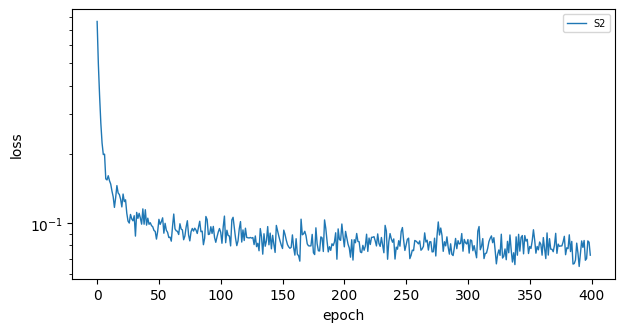

In [31]:
fig, ax = plt.subplots(figsize=(7,3.5))
for s in done('diffusion_loss'):
    ax.plot(J(s,'diffusion_loss')['loss'], label=s, lw=1)
ax.set_yscale('log'); ax.set_xlabel('epoch'); ax.set_ylabel('loss'); ax.legend(ncol=5, fontsize=7); plt.show()

### 11.3. Real vs synthetic windows (latest finished fold)
Black = real (from training subjects), blue = diffusion samples. Synthetic should look similar: smooth tonic level, with SCR bumps more common in stress.

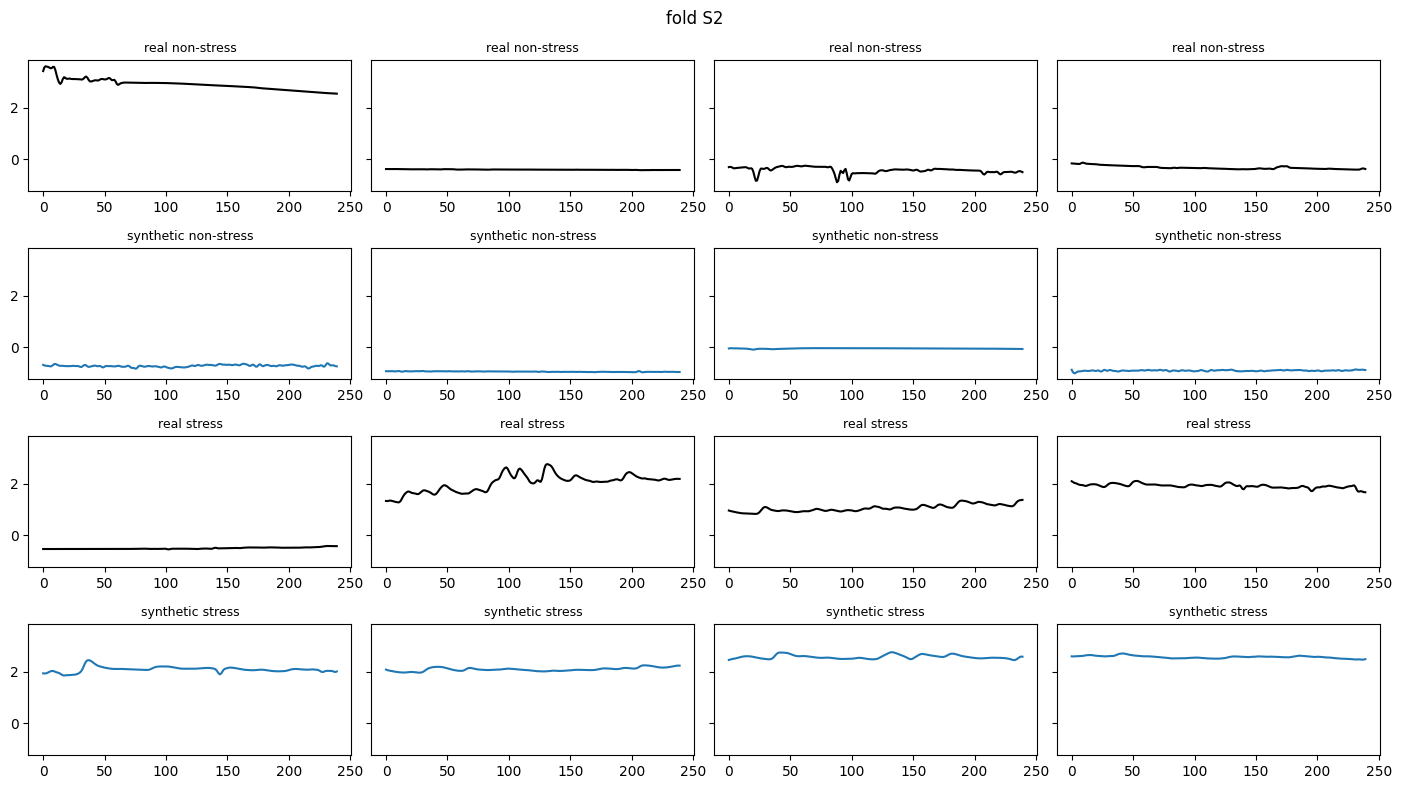

In [32]:
have = [s for s in SUBJ if (FOLDS_DIR/s/'samples.npz').exists()]
if have:
    s = have[-1]; z = np.load(FOLDS_DIR/s/'samples.npz'); X, y = z['X'], z['y']
    others = [o for o in SUBJ if o != s][:4]
    fig, ax = plt.subplots(4, 4, figsize=(14, 8), sharey=True)
    for r, c in enumerate((0, 1)):
        real = [load_subject(o)[0][load_subject(o)[1]==c][::9][0] for o in others]
        for j in range(4):
            ax[2*r, j].plot(real[j], 'k'); ax[2*r, j].set_title('real ' + ['non-stress','stress'][c], fontsize=9)
            ax[2*r+1, j].plot(X[y==c][j], 'C0'); ax[2*r+1, j].set_title('synthetic ' + ['non-stress','stress'][c], fontsize=9)
    fig.suptitle(f'fold {s}'); plt.tight_layout(); plt.show()
else:
    print('no samples yet')

### 11.4. Fidelity (Test 0)
Compare each synthetic metric with its `_testreal` reference (how far an **unseen real person** is from the training data). Synthetic ≲ reference = good.
- `disc` = |acc − 0.5| of a real-vs-synthetic classifier (0 = indistinguishable)

In [33]:
rows = []
for s in done('fidelity'):
    f = J(s,'fidelity')
    for c in ('nonstress','stress'):
        r = f[c]
        rows.append({'fold': s, 'class': c, 'mmd': r['mmd'], 'mmd_testreal': r['mmd_testreal'],
                     'psd': r['psd_logrmse'], 'psd_testreal': r['psd_logrmse_testreal'],
                     'dtw_syn-real': r['dtw_synth_real'], 'dtw_real-real': r['dtw_real_real'],
                     'SCL real': r['eda']['scl']['real_mean'], 'SCL syn': r['eda']['scl']['synth_mean'],
                     'SCR/min real': r['eda']['scr_rate']['real_mean'], 'SCR/min syn': r['eda']['scr_rate']['synth_mean'],
                     'disc': f['discriminative_score']})
fid = pd.DataFrame(rows)
if len(fid):
    display(fid.groupby('class').mean(numeric_only=True).T.rename(columns=lambda c: c+' (mean over folds)'))
    display(fid)
else:
    print('no fidelity yet')

class,nonstress (mean over folds),stress (mean over folds)
mmd,8.247e-04,0.009
mmd_testreal,1.475e-02,0.077
psd,2.860e-01,0.649
psd_testreal,3.970e-01,1.070
dtw_syn-real,5.855e-01,0.972
dtw_real-real,6.087e-01,1.033
SCL real,-4.844e-01,1.576
SCL syn,-5.778e-01,1.679
SCR/min real,2.375e+01,16.460
SCR/min syn,2.926e+01,15.253


,fold,class,mmd,mmd_testreal,psd,psd_testreal,dtw_syn-real,dtw_real-real,SCL real,SCL syn,SCR/min real,SCR/min syn,disc
0,S2,nonstress,8.247e-04,0.015,0.286,0.397,0.585,0.609,-0.484,-0.578,23.75,29.263,0.088
1,S2,stress,9.459e-03,0.077,0.649,1.070,0.972,1.033,1.576,1.679,16.46,15.253,0.088


### 11.5. Utility (Test 1): the key result
Macro-F1 on the **held-out subject**, averaged over 3 classifier seeds, then over finished folds.
- A = 100% real · B = 100% synthetic · C = small real + diffusion · D = small real only · E = + SMOTE · F = + augmentation
- **Key question: is C > D, especially at small fractions?**

macro-F1, mean over 1 folds


variant,A,B,C,D,E,F
frac,,,,,,
0.05,NaN,NaN,0.886,0.866,0.897,0.863
0.10,NaN,NaN,0.897,0.879,0.889,0.890
0.25,NaN,NaN,0.899,0.904,0.915,0.872
0.50,NaN,NaN,0.902,0.895,0.889,0.865
1.00,0.893,0.877,0.910,0.893,0.906,0.878


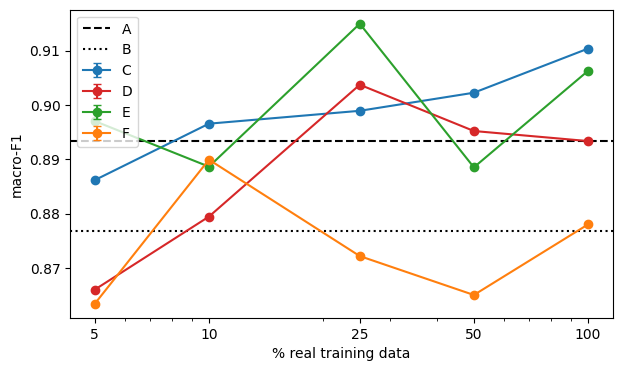

C − D per held-out subject (positive = synthetic helped):


,5%,10%,25%,50%,100%
fold,,,,,
S2,0.02,0.017,-0.005,0.007,0.017


In [34]:
rows = []
for s in done('utility'):
    for r in J(s,'utility'): rows.append({**r, 'fold': s})
if rows:
    u = pd.DataFrame(rows).groupby(['fold','variant','frac'], as_index=False)[['macro_f1','bal_acc']].mean()
    tab = u.groupby(['variant','frac']).macro_f1.agg(['mean','std']).unstack(0)
    print(f'macro-F1, mean over {u.fold.nunique()} folds'); display(tab['mean'].round(3))
    fig, ax = plt.subplots(figsize=(7,4))
    col = dict(C='C0', D='C3', E='C2', F='C1')
    for v in 'CDEF':
        d = u[u.variant==v].groupby('frac').macro_f1.agg(['mean','sem'])
        ax.errorbar(d.index*100, d['mean'], yerr=d['sem'].fillna(0), marker='o', capsize=3, label=v, color=col[v])
    for v, ls in (('A','--'),('B',':')):
        ax.axhline(u[u.variant==v].macro_f1.mean(), ls=ls, color='k', label=v)
    ax.set_xscale('log'); ax.set_xticks([5,10,25,50,100],['5','10','25','50','100'])
    ax.set_xlabel('% real training data'); ax.set_ylabel('macro-F1'); ax.legend(); plt.show()
    p = u.pivot_table(index='fold', columns=['variant','frac'], values='macro_f1')
    diff = pd.DataFrame({f'{int(f*100)}%': p[('C',f)] - p[('D',f)] for f in cfg['utility']['fractions']})
    print('C − D per held-out subject (positive = synthetic helped):'); display(diff.round(3))
else:
    print('no utility yet')

### 11.6. Memorization audit (Test 2)
- `dcr_ratio` = median DCR(synthetic → train) / median DCR(unseen real → train). **< 1 means closer to the training data than a new person is (possible copying)**
- `frac<p5` = share of synthetic windows closer than the 5th percentile of unseen-real DCR (≈0.05 expected if no copying)
- `mia_auc` = membership inference AUC (0.5 = no signal)
- re-ID: subject-classifier confidence on synthetic vs. known subjects vs. an unseen subject

,dcr_ratio,frac<p5,nndr_syn,nndr_ref,mia_auc,subj_chi2_p,max_subj_overrep,reid_acc_known,conf_known,conf_synth,conf_unseen
fold,,,,,,,,,,,
S2,1.414,0.09,0.942,0.932,0.574,2.422e-64,1.857,0.264,0.36,0.307,0.26


,dcr_ratio,frac<p5,nndr_syn,nndr_ref,mia_auc,subj_chi2_p,max_subj_overrep,reid_acc_known,conf_known,conf_synth,conf_unseen
mean,1.414,0.09,0.942,0.932,0.574,2.422e-64,1.857,0.264,0.36,0.307,0.26


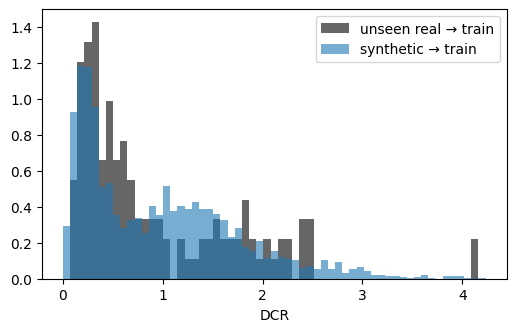

In [35]:
rows = []
for s in done('memorization'):
    m = J(s,'memorization'); r = m['reid']
    rows.append({'fold': s, 'dcr_ratio': m['dcr']['dcr_ratio'], 'frac<p5': m['dcr']['frac_synth_below_ref_p5'],
                 'nndr_syn': m['dcr']['nndr_synth_median'], 'nndr_ref': m['dcr']['nndr_ref_median'], 'mia_auc': m['mia_auc'],
                 'subj_chi2_p': m['per_subject']['chi2_p'], 'max_subj_overrep': m['per_subject']['max_over_expected'],
                 'reid_acc_known': r['reid_acc_heldout_known'], 'conf_known': r['maxprob_known_subject'],
                 'conf_synth': r['maxprob_synthetic'], 'conf_unseen': r['maxprob_unseen_subject']})
mem = pd.DataFrame(rows)
if len(mem):
    display(mem.set_index('fold')); display(mem.mean(numeric_only=True).to_frame('mean').T)
    a = [np.load(FOLDS_DIR/s/'dcr_arrays.npz') for s in done('memorization')]
    ds, dr = np.concatenate([x['dcr_synth'] for x in a]), np.concatenate([x['dcr_ref'] for x in a])
    b = np.linspace(0, np.percentile(np.r_[ds,dr], 99), 60)
    plt.figure(figsize=(6,3.5)); plt.hist(dr, b, density=True, alpha=.6, color='k', label='unseen real → train')
    plt.hist(ds, b, density=True, alpha=.6, label='synthetic → train'); plt.xlabel('DCR'); plt.legend(); plt.show()
else:
    print('no memorization yet')

### 11.7. Utility–memorization trade-off curves
Each point = one generator setting. x = DCR ratio (left = more memorization), y = macro-F1 of C @ 10% real.

epoch fraction


,util_C10_f1,dcr_ratio,mia_auc
setting,,,
0.25,0.904,2.237,0.547
0.50,0.900,1.510,0.568
1.00,0.897,1.414,0.574


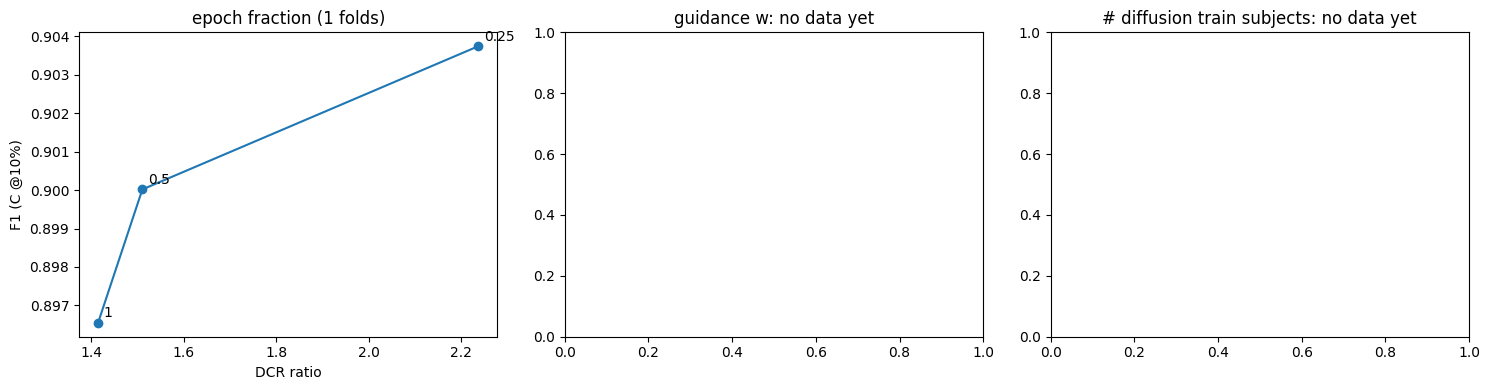

In [36]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for j, (name, lab) in enumerate((('curve_epochs','epoch fraction'),('curve_guidance','guidance w'),('curve_subjects','# diffusion train subjects'))):
    rows = [{'setting': float(k), **{m: v[m] for m in ('util_C10_f1','dcr_ratio','mia_auc')}} for s in done(name) for k, v in J(s,name).items()]
    if not rows:
        ax[j].set_title(f'{lab}: no data yet'); continue
    d = pd.DataFrame(rows).groupby('setting').mean()
    ax[j].plot(d.dcr_ratio, d.util_C10_f1, 'o-')
    for k, r in d.iterrows(): ax[j].annotate(f'{k:g}', (r.dcr_ratio, r.util_C10_f1), xytext=(4,4), textcoords='offset points')
    ax[j].set_xlabel('DCR ratio'); ax[j].set_ylabel('F1 (C @10%)'); ax[j].set_title(f'{lab} ({len(done(name))} folds)')
    print(lab); display(d.round(3))
plt.tight_layout(); plt.show()

### 11.8. Replacement + mixed-set property check
The real set is 100%, with r% of windows swapped for synthetic ones (random vs. stress-only). Compare with A (0% replaced).

In [37]:
rows = [{**r, 'fold': s} for s in done('replacement') for r in J(s,'replacement')]
if rows:
    rp = pd.DataFrame(rows).groupby(['fold','mode','rate'], as_index=False).macro_f1.mean()
    display(rp.groupby(['mode','rate']).macro_f1.agg(['mean','std']).unstack(0).round(3))
else:
    print('no replacement yet')
props = {s: J(s,'property') for s in done('property')}
if props:
    print('label consistency (does a real-trained classifier agree with the conditioned label?)')
    display(pd.DataFrame({s: p['label_consistency'] for s, p in props.items()}).T.rename(columns={'0':'non-stress','1':'stress'}))

no replacement yet
